# STIR Coherence and Budget Aware Admission

A reproducible **synthetic quantum-network simulation**, not a hardware experiment or an implementation of RADAR-Q or Q-GUARD. The proposed contribution is the coupling of epoch-fenced request authority, a conservative Werner-state coherence admission certificate, and bounded path probing with stale resource prices. Deterministic mapping and fidelity-aware routing are established ideas, not claimed inventions.

Run all cells in order. Requires Python 3.10+, NumPy, pandas, SciPy and Matplotlib. No external datasets, credentials or internet are needed. Results are written to `stir_outputs/`. Default study uses ten independent paired seeds. Changing parameters reruns the study; figures never use hard-coded performance values.

## Research questions
1. What qualified goodput versus message-cost tradeoff does conservative coherence admission produce?
2. Does stale-price path selection help under contention, and how sensitive is it to epoch length and probe budget?
3. Which claims fail under inconsistent epochs, retries and an observable ownership oracle?

The simulator models exclusive path reservations with explicit setup delays and counts control messages. Atomic acquisition is an abstraction of ordered local acquisition with rollback; distributed packet delivery, partitions, purification, and hardware calibration remain unvalidated.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.stats import t as student_t
import math, hashlib, hmac, heapq, json, platform, time
from collections import Counter
from functools import lru_cache
OUT = Path('stir_outputs'); OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':120, 'savefig.dpi':220, 'font.size':10, 'axes.spines.top':False, 'axes.spines.right':False})

FIGURE_COUNTER = 0
def publish_figures():
    """Save every figure and display it in notebook frontends when available."""
    global FIGURE_COUNTER
    for number in plt.get_fignums():
        fig = plt.figure(number); FIGURE_COUNTER += 1
        stem = f'Fig{FIGURE_COUNTER:02d}'
        png = OUT / (stem + '.png')
        fig.savefig(png, bbox_inches='tight')
        fig.savefig(OUT / (stem + '.pdf'), bbox_inches='tight')
        try:
            from IPython.display import display, Image
            display(Image(filename=str(png)))
        except ImportError:
            print('Saved', png)
        plt.close(fig)
plt.show = publish_figures

SEEDS=list(range(10))
POLICIES=['Static STIR','Keyed HRW','Fidelity greedy','Central oracle','CB-STIR','No certificate','No prices']
COLORS=dict(zip(POLICIES,plt.cm.tab10.colors[:7]))
print('Python',platform.python_version(),'NumPy',np.__version__,'pandas',pd.__version__)
print('Independent seeds:',SEEDS)


Python 3.14.6 NumPy 2.4.6 pandas 3.0.3
Independent seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


## Model and conservative certificate
Each link produces a Werner pair with visibility $w_e=(4F_e-1)/3$, independent geometric generation time $G_e$ (support $1,2,\ldots$), and effective pair-visibility lifetime $T$. Conditional on successful swaps,
$$F_P=\frac{1+3v_s^{h-1}\prod_{e\in P}w_e\exp[-\sum_e a_e/T]}{4}.$$
Here $a_e=G_{\max}-G_e+(h-1)d_s$. All links start after reservation completes; pre-generation control delay affects deadlines and capacity but does not age nonexistent pairs. $T$ is an effective two-qubit depolarizing visibility lifetime, not asserted to equal a device's measured $T_2$.

For $g=\lceil\log(\alpha/h)/\log(1-p_{\min})\rceil$, the union bound gives $\Pr(G_{\max}\le g)\ge1-\alpha$. Thus $a_e\le g-1+(h-1)d_s$ and
$$F_{LB}=\{1+3v_s^{h-1}\prod_e w_e\exp[-h(g-1+(h-1)d_s)/T]\}/4.$$
Admit only if $F_{LB}\ge F_{min}$, setup plus generation plus swaps fits the deadline, and the candidate probe fits the budget. The fidelity probability guarantee is conditional on swap success and model correctness. It is not a guarantee of request success or of capacity availability.

Physical parameters are illustrative, not measured. No purification is simulated.

In [2]:
KEY=b'public-reproducibility-key-not-a-production-secret'
def stable_int(*parts):
    return int.from_bytes(hashlib.sha256(repr(parts).encode()).digest()[:8],'big')
def owner(tenant,seat,epoch,n=6,weights=None):
    if weights is None: weights=np.ones(n)
    scores=[]
    for i in range(n):
        digest=hmac.new(KEY,repr((tenant,seat,epoch,i)).encode(),hashlib.sha256).digest()
        u=(int.from_bytes(digest[:8],'big')+0.5)/2**64
        scores.append(-math.log(min(u,1-1e-16))/weights[i])
    return min(range(n),key=lambda i:(scores[i],i))
def edge(a,b): return (min(a,b),max(a,b))
def make_graph(kind,n,seed):
    rng=np.random.default_rng(seed); adj={i:set() for i in range(n)}
    def add(a,b):
        if a!=b: adj[a].add(b); adj[b].add(a)
    if kind=='grid':
        side=int(math.sqrt(n)); assert side*side==n
        for i in range(n):
            if i%side<side-1:add(i,i+1)
            if i+side<n:add(i,i+side)
    else:
        for i in range(n): add(i,(i+1)%n); add(i,(i+2)%n)
        for _ in range(n//2): add(*rng.choice(n,2,replace=False))
    props={}
    for a in adj:
        for b in sorted(adj[a]):
            if a<b:props[a,b]={'p':float(rng.uniform(.55,.9)), 'F':float(rng.uniform(.985,.998))}
    return adj,props
@lru_cache(maxsize=20000)
def candidate_paths(adj_tuple,src,dst,k=4):
    adj=dict(adj_tuple); q=[(0,(src,))]; out=[]; expansions=0
    while q and len(out)<k and expansions<30000:
        _,p=heapq.heappop(q); expansions+=1
        if p[-1]==dst:out.append(p);continue
        if len(p)>10:continue
        for v in adj[p[-1]]:
            if v not in p:heapq.heappush(q,(len(p),p+(v,)))
    return out
SWAP_P=.96; SWAP_V=.998; SWAP_DELAY=1; ALPHA=.10
# One slot is an illustrative millisecond, with one link attempt per slot.
def certificate(path,props,T,alpha=ALPHA):
    es=[edge(a,b) for a,b in zip(path,path[1:])]; h=len(es)
    pmin=min(props[e]['p'] for e in es)
    g=int(math.ceil(math.log(alpha/h)/math.log(1-pmin)))
    wprod=np.prod([(4*props[e]['F']-1)/3 for e in es])
    lower=(1+3*wprod*SWAP_V**(h-1)*math.exp(-h*(g-1+(h-1)*SWAP_DELAY)/T))/4
    return lower,g

def simulate(kind='smallworld',n=25,seed=0,rate=.8,T=100,horizon=1000,
             policy='CB-STIR',epoch_len=20,budget=32,K=4,Fmin=.72,skew=.6,msg_delay=.15):
    adj,props=make_graph(kind,n,seed)
    at=tuple((a,tuple(sorted(adj[a]))) for a in sorted(adj))
    rng=np.random.default_rng(10000+seed); arrivals=[]
    # Common request stream across policies. Arrival and physical randomness separated.
    for tick in range(horizon):
        for _ in range(rng.poisson(rate)):
            tenant=int(rng.integers(4)); seat=int(rng.integers(64))
            src=int(rng.integers(n)); dst=int(rng.integers(n-1));dst+=dst>=src
            if rng.random()<skew:src=tenant % n; dst=n-1-tenant
            arrivals.append((tick,tenant,seat,src,dst))
    node_used=np.zeros(n,dtype=int); link_used={e:0 for e in props}; capacity=6
    prices=np.zeros(n); events=[]; counter=0; logs=[]; messages=Counter(); latest=-1
    accepted=np.zeros(6,dtype=int); node_max=0; mem_area=0; attempts_total=0
    def release(job):
        nonlocal attempts_total
        for v,d in job['needs'].items():node_used[v]-=d
        for e in job['edges']:link_used[e]-=1
        messages['release']+=2*len(job['edges']); attempts_total+=job['attempts']
        logs.append(job['record'])
    def finish_until(tick):
        while events and events[0][0]<=tick:
            _,_,job=heapq.heappop(events);release(job)
    for req_id,(tick,tenant,seat,src,dst) in enumerate(arrivals):
        finish_until(tick)
        epoch=tick//epoch_len
        if epoch!=latest and policy in ['CB-STIR','No certificate']:
            prices=node_used/capacity;latest=epoch
        # Every policy pays epoch membership/key manifest delivery. Adaptive price piggybacks.
        # Full epoch accounting is added below, independent of request arrivals.
        who=owner(tenant,seat,epoch)
        messages['authority']+=2
        paths=candidate_paths(at,src,dst,K)
        def priority(p):
            h=len(p)-1; quality=np.prod([(4*props[edge(a,b)]['F']-1)/3 for a,b in zip(p,p[1:])])
            if policy=='Central oracle':price=sum(node_used[v]/capacity for v in p)
            elif policy in ['CB-STIR','No certificate']:price=sum(prices[v] for v in p)
            else:price=0
            if policy in ['Static STIR','Keyed HRW']:return h
            if policy=='Fidelity greedy':return -quality*SWAP_V**(h-1)
            return h+.8*price-2*quality
        paths=sorted(paths,key=lambda p:(priority(p),p))
        if policy=='Static STIR':paths=paths[:1]
        rec={'request_id':req_id,'seed':seed,'policy':policy,'tenant':tenant,'owner':who,
             'arrival':tick,'status':'capacity_reject','latency':np.nan,'fidelity':np.nan,
             'predicted_lower':np.nan,'hops':np.nan,'probes':0,'setup':np.nan}
        probe_cost=0; chosen=None; reason='capacity_reject'
        use_cert=policy in ['CB-STIR','No prices']
        for path in paths:
            h=len(path)-1; lower,g=certificate(path,props,T)
            if use_cert and lower<Fmin:reason='certificate_reject';continue
            # B bounds request-specific probe request/reply messages, not physical heralding.
            cost=2*(h+1)
            if policy in ['CB-STIR','No certificate','No prices'] and probe_cost+cost>budget:
                reason='budget_reject';break
            probe_cost+=cost;messages['probe']+=cost;rec['probes']+=1
            needs={v:(1 if v in (src,dst) else 2) for v in path}
            es=[edge(a,b) for a,b in zip(path,path[1:])]
            if any(node_used[v]+d>capacity for v,d in needs.items()) or any(link_used[e] for e in es):continue
            setup=int(math.ceil(msg_delay*(2*h+probe_cost)))
            if use_cert and setup+g+(h-1)*SWAP_DELAY>30:reason='deadline_reject';continue
            chosen=(path,es,needs,setup,lower);break
        if chosen is None:
            rec['status']=reason;logs.append(rec);continue
        path,es,needs,setup,lower=chosen;h=len(es)
        prng=np.random.default_rng(stable_int(seed,req_id,'physics'))
        # Edge-specific random substream keeps same edge generation draws across path choices.
        gs=np.array([np.random.default_rng(stable_int(seed,req_id,e)).geometric(props[e]['p']) for e in es])
        gen=int(gs.max());swap_time=(h-1)*SWAP_DELAY; capgen=max(1,30-setup-swap_time)
        elapsed=min(gen,capgen);duration=setup+elapsed+swap_time
        ages=gen-gs+swap_time
        w=np.prod([(4*props[e]['F']-1)/3 for e in es])*SWAP_V**(h-1)*np.exp(-ages.sum()/T)
        fidelity=float((1+3*w)/4)
        if gen>capgen:status='timeout';fidelity=np.nan
        elif prng.random()>SWAP_P**(h-1):status='swap_failure';fidelity=np.nan
        elif fidelity<Fmin:status='low_fidelity'
        else:status='qualified'
        messages['reservation']+=4*h
        att=int(np.minimum(gs,elapsed).sum());messages['herald']+=2*att
        if gen<=capgen:messages['swap']+=2*(h-1)
        for v,d in needs.items():node_used[v]+=d
        for e in es:link_used[e]+=1
        assert max(node_used)<=capacity and min(node_used)>=0
        assert max(link_used.values())<=1
        node_max=max(node_max,int(max(node_used)));mem_area+=sum(needs.values())*duration
        accepted[who]+=1
        rec.update(status=status,latency=duration,fidelity=fidelity,predicted_lower=lower,hops=h,setup=setup)
        job={'needs':needs,'edges':es,'attempts':att,'record':rec}
        counter+=1;heapq.heappush(events,(tick+duration,counter,job))
    finish_until(float('inf'));assert not node_used.any() and not any(link_used.values())
    epochs=int(math.ceil(horizon/epoch_len));messages['epoch_manifest']=2*n*epochs
    # Central exact-state oracle receives update messages, not invented N-node per-request polls.
    if policy=='Central oracle':messages['state_updates']=4*sum(1 for r in logs if not np.isnan(r['hops']))
    df=pd.DataFrame(logs).sort_values('request_id');q=df[df.status=='qualified']
    completion_counts=q.groupby('tenant').size().reindex(range(4),fill_value=0).to_numpy()
    fairness=completion_counts.sum()**2/(4*np.square(completion_counts).sum()) if completion_counts.sum() else np.nan
    total=sum(messages.values());qual=len(q);admitted=int(df.hops.notna().sum())
    summary={'seed':seed,'policy':policy,'topology':kind,'n':n,'rate':rate,'T':T,'epoch_len':epoch_len,
       'budget':budget,'K':K,'horizon':horizon,'Fmin':Fmin,'skew':skew,'msg_delay':msg_delay,
       'requests':len(df),'admitted':admitted,'qualified':qual,'goodput':qual/horizon,
       'success_fraction':qual/max(len(df),1),'conditional_qualified':qual/max(admitted,1),
       'messages':total,'messages_per_qualified':total/qual if qual else np.nan,
       'p95_latency':float(q.latency.quantile(.95)) if qual else np.nan,
       'mean_fidelity':float(q.fidelity.mean()) if qual else np.nan,'fairness':fairness,
       'memory_utilization':mem_area/(n*capacity*horizon),'peak_memory':node_max,
       'authority_cv':float(np.std(accepted)/np.mean(accepted)) if admitted else np.nan,
       'attempts':attempts_total,'active_repeaters_per_admitted':float((df.hops.dropna()-1).mean())}
    summary.update({'msg_'+k:v for k,v in messages.items()})
    return summary,df

# Meaningful invariants and limiting cases.
a,p=make_graph('grid',9,0);path=(0,1,2)
lo,g=certificate(path,p,1e12)
w=np.prod([(4*p[edge(u,v)]['F']-1)/3 for u,v in zip(path,path[1:])])
assert abs(lo-(1+3*w*SWAP_V)/4)<1e-8
assert certificate(path,p,20)[0]<certificate(path,p,100)[0]
assert all(owner(1,3,0)==owner(1,3,0) for _ in range(20))
assert (1-(1-min(p[edge(u,v)]['p'] for u,v in zip(path,path[1:])))**g)>0
s,d=simulate(n=9,kind='grid',horizon=100,seed=0)
assert s['requests']==len(d) and s['qualified']<=s['admitted']<=s['requests']
print('Mapping determinism, certificate monotonicity, no-decoherence limit, accounting and resource invariants passed.')


Mapping determinism, certificate monotonicity, no-decoherence limit, accounting and resource invariants passed.


## Paired multi-scenario study
Seven policies share graph seeds, request streams, capacity, deadline, link physics, swap model, and reservation costs. Central oracle has instantaneous capacity knowledge without per-request global polling; it is a strong idealized comparator. Fidelity greedy is a local heuristic, not a reproduction of a published protocol. A rejected request is dropped immediately; no ingress waiting queue is modeled. Events admitted before the horizon are drained, so goodput is completed pairs per arrival-window millisecond (boundary bias bounded by the 30 ms deadline). Conditional latency excludes failures and must be interpreted alongside success fraction.

CB-STIR uses a four-path static catalog, a 32-message probing cap, and a 20 ms epoch. Manifest delivery is counted for every policy. Epoch prices cost no extra packets under the specified piggyback model, but use additional payload bytes; bytes are not yet modeled. Candidate generation uses static global topology at configuration time, never fresh global entanglement state.

In [3]:
rows=[]; request_frames=[]
start=time.time()
for kind in ['grid','smallworld']:
    for rate in [.3,.8,1.5]:
        for T in [40,100]:
            for seed in SEEDS:
                for policy in POLICIES:
                    s,d=simulate(kind=kind,seed=seed,rate=rate,T=T,policy=policy)
                    rows.append(s)
                    if kind=='smallworld' and rate==.8 and T==100:
                        d['topology']=kind;request_frames.append(d)
results=pd.DataFrame(rows)
requests=pd.concat(request_frames,ignore_index=True)
results.to_csv(OUT/'experiment_summary.csv',index=False)
requests.to_csv(OUT/'representative_request_traces.csv',index=False)
print('Completed',len(results),'independent simulation runs in',round(time.time()-start,1),'seconds')
print(results.groupby('policy')[['goodput','success_fraction','messages_per_qualified','fairness']].mean().round(3).to_string())


Completed 840 independent simulation runs in 1435.4 seconds
                 goodput  success_fraction  messages_per_qualified  fairness
policy                                                                      
CB-STIR            0.402             0.503                  56.003     0.957
Central oracle     0.411             0.523                 145.551     0.961
Fidelity greedy    0.393             0.504                 150.680     0.965
Keyed HRW          0.404             0.518                 142.690     0.956
No certificate     0.406             0.517                 103.704     0.959
No prices          0.399             0.501                  56.429     0.958
Static STIR        0.350             0.450                  88.912     0.932


## Statistics
Seed is the replication unit. For each scenario, differences are paired by seed; 95% Student t intervals describe the mean seed difference. We do not treat individual requests as independent replicates. The confidence intervals are descriptive over chosen synthetic topologies and seeds, not evidence of population-wide superiority. Multiple scenario comparisons are exploratory. Zero qualified completions produce undefined per-success ratios rather than infinity disguised as a finite result.

In [4]:
def mean_ci(values):
    v=np.asarray(values,dtype=float);v=v[np.isfinite(v)]
    if len(v)<2:return (float(v.mean()) if len(v) else np.nan,np.nan)
    return float(v.mean()),float(student_t.ppf(.975,len(v)-1)*v.std(ddof=1)/np.sqrt(len(v)))
paired=[]
for (kind,rate,T),sub in results.groupby(['topology','rate','T']):
    for metric in ['goodput','messages_per_qualified','success_fraction']:
        piv=sub.pivot(index='seed',columns='policy',values=metric)
        for base in ['Static STIR','Keyed HRW','Fidelity greedy','Central oracle','No certificate','No prices']:
            vals=piv['CB-STIR']-piv[base];mean,ci=mean_ci(vals)
            paired.append(dict(topology=kind,rate=rate,T=T,metric=metric,baseline=base,
                               difference=mean,ci_low=mean-ci,ci_high=mean+ci,n_pairs=vals.notna().sum()))
paired=pd.DataFrame(paired);paired.to_csv(OUT/'paired_confidence_intervals.csv',index=False)
print(paired.query("topology=='smallworld' and rate==.8 and T==100 and metric=='goodput'").round(4).to_string(index=False))


  topology  rate   T  metric        baseline  difference  ci_low  ci_high  n_pairs
smallworld   0.8 100 goodput     Static STIR      0.1070  0.0963   0.1177       10
smallworld   0.8 100 goodput       Keyed HRW      0.0022 -0.0072   0.0116       10
smallworld   0.8 100 goodput Fidelity greedy      0.0158  0.0057   0.0259       10
smallworld   0.8 100 goodput  Central oracle     -0.0108 -0.0154  -0.0062       10
smallworld   0.8 100 goodput  No certificate     -0.0001 -0.0003   0.0001       10
smallworld   0.8 100 goodput       No prices      0.0057 -0.0022   0.0136       10


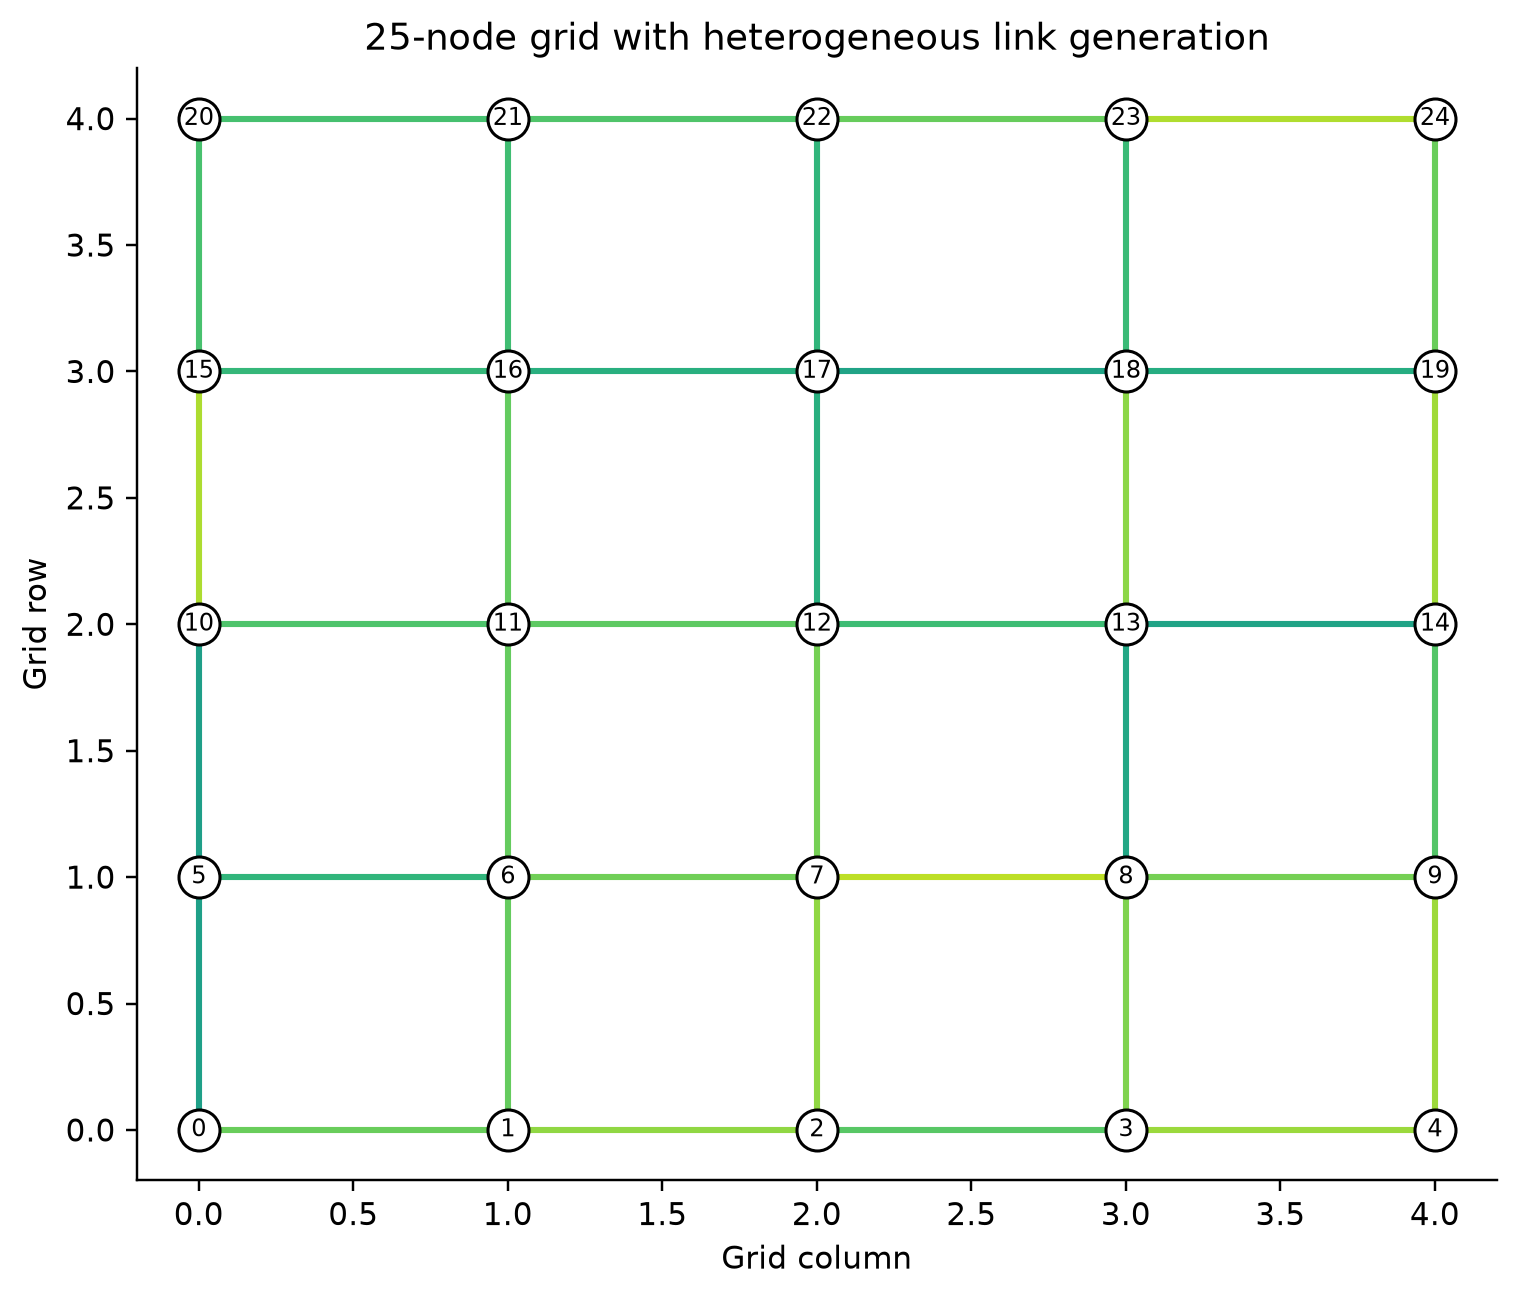

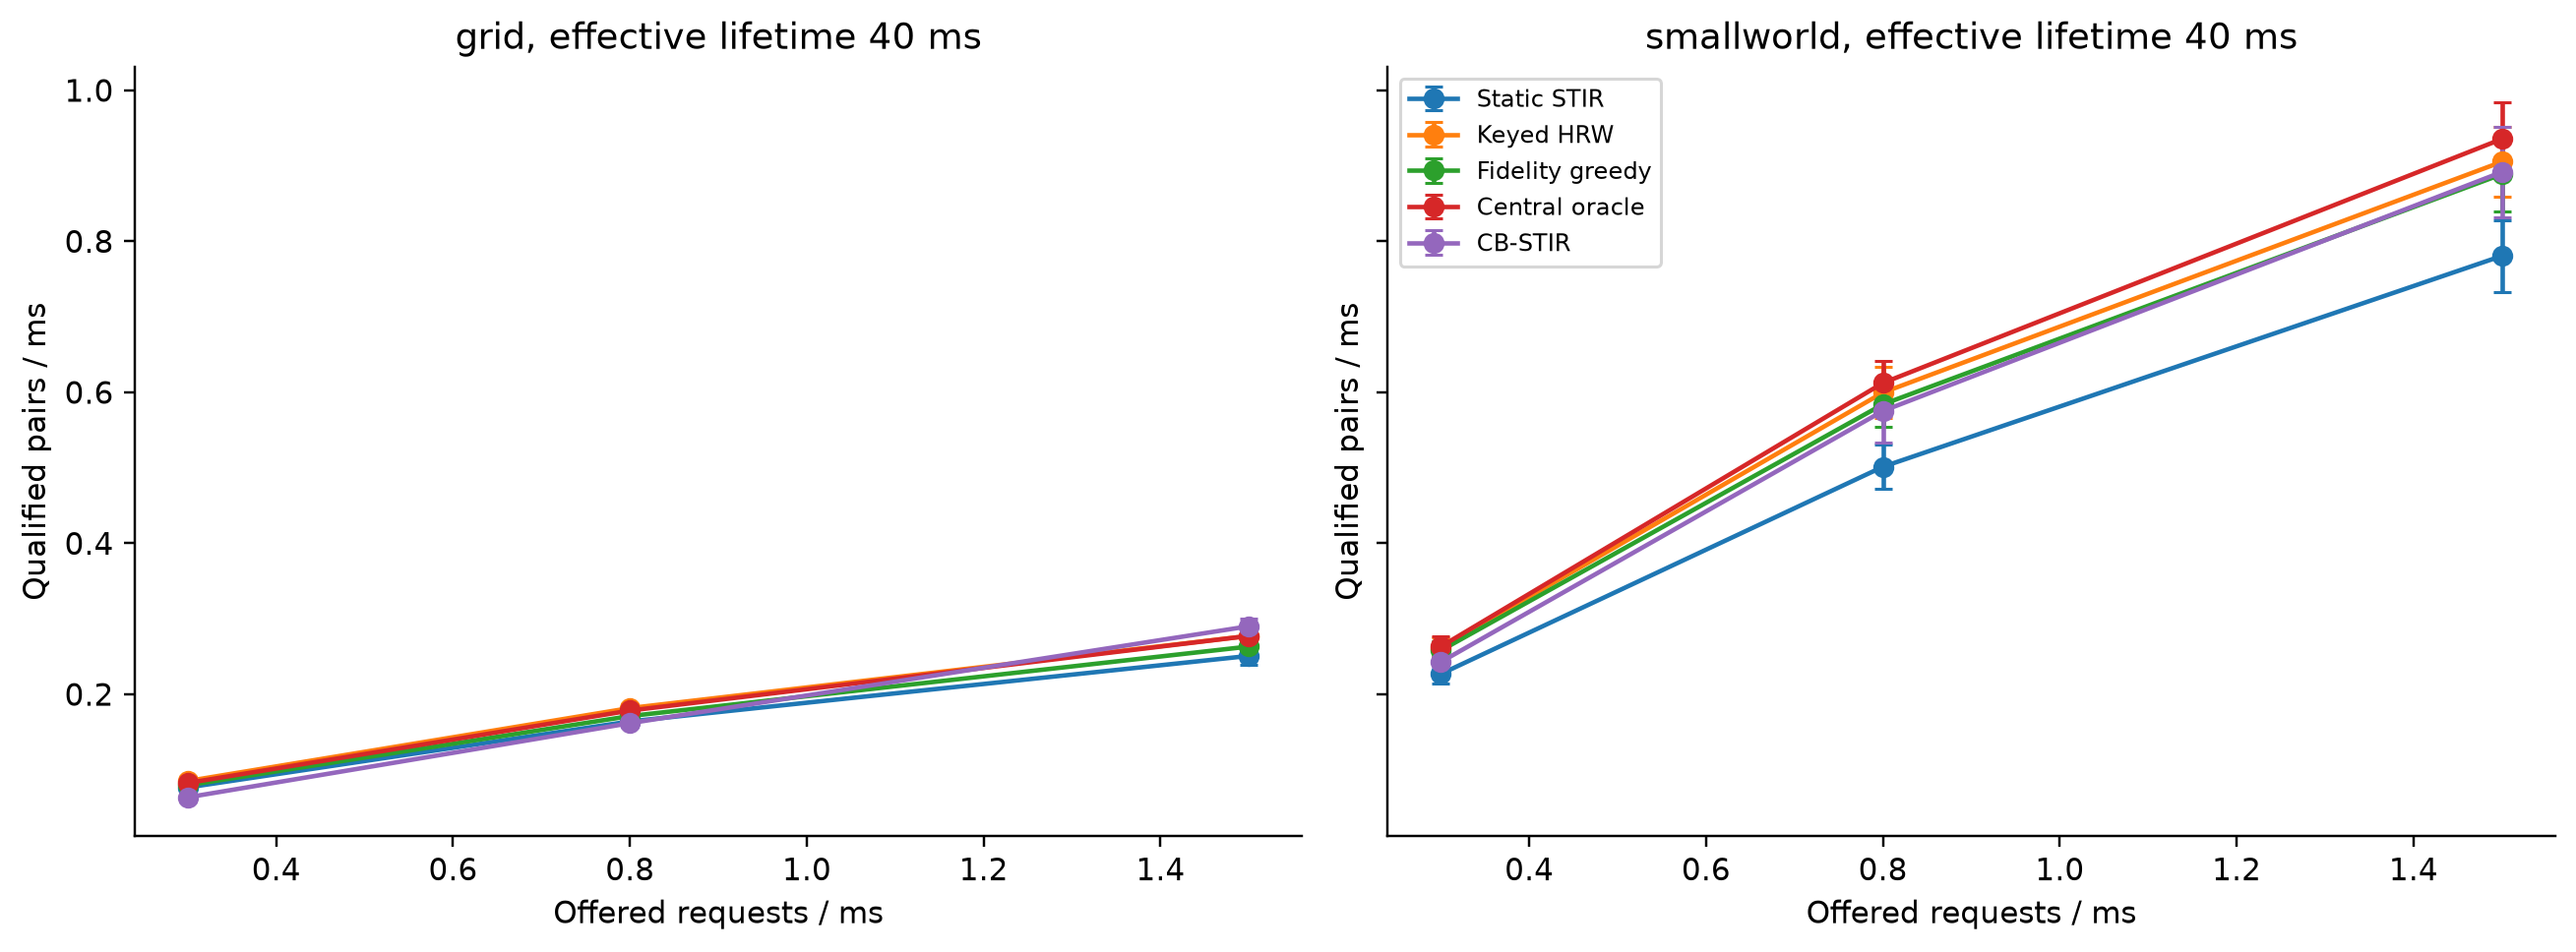

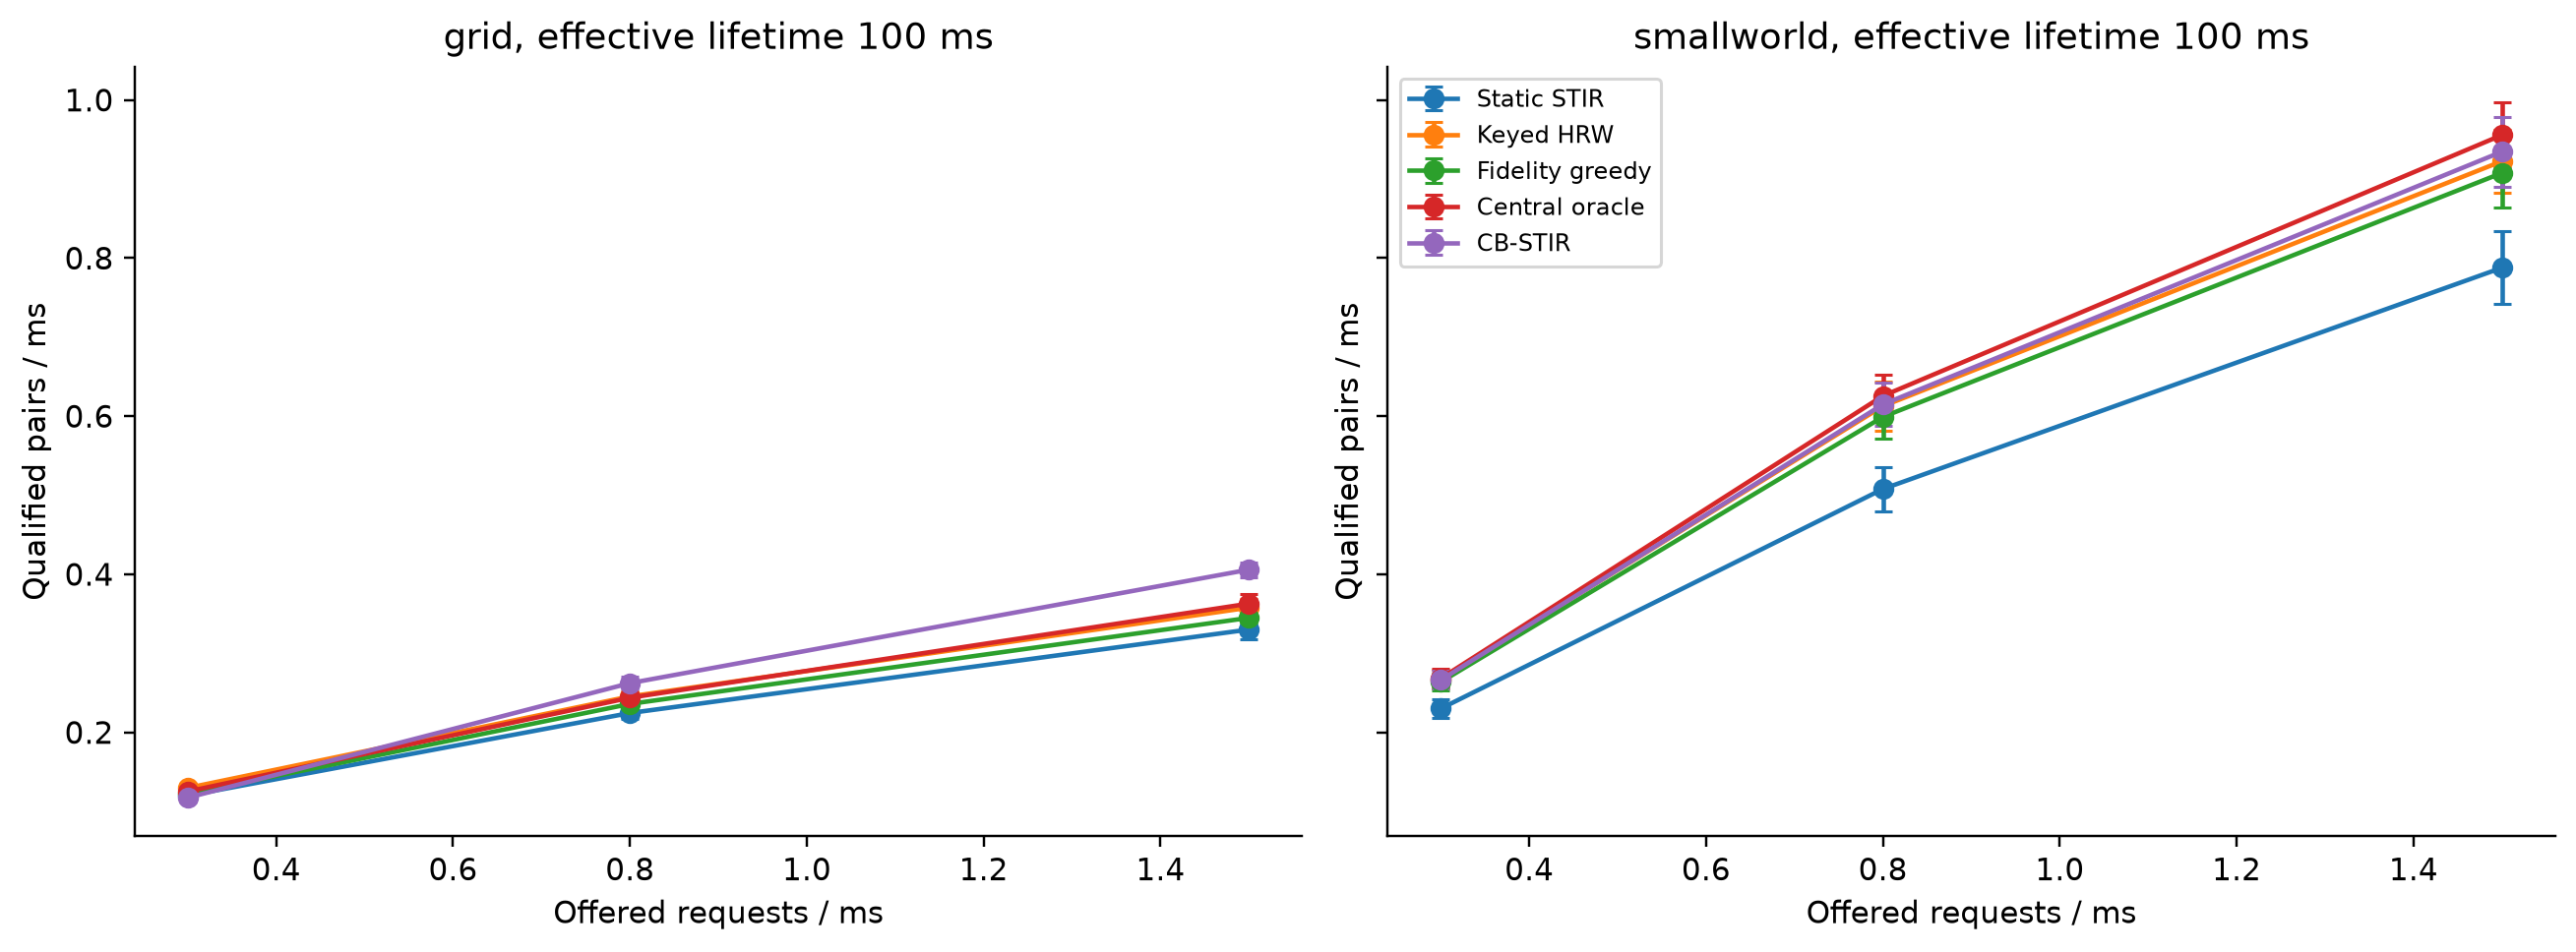

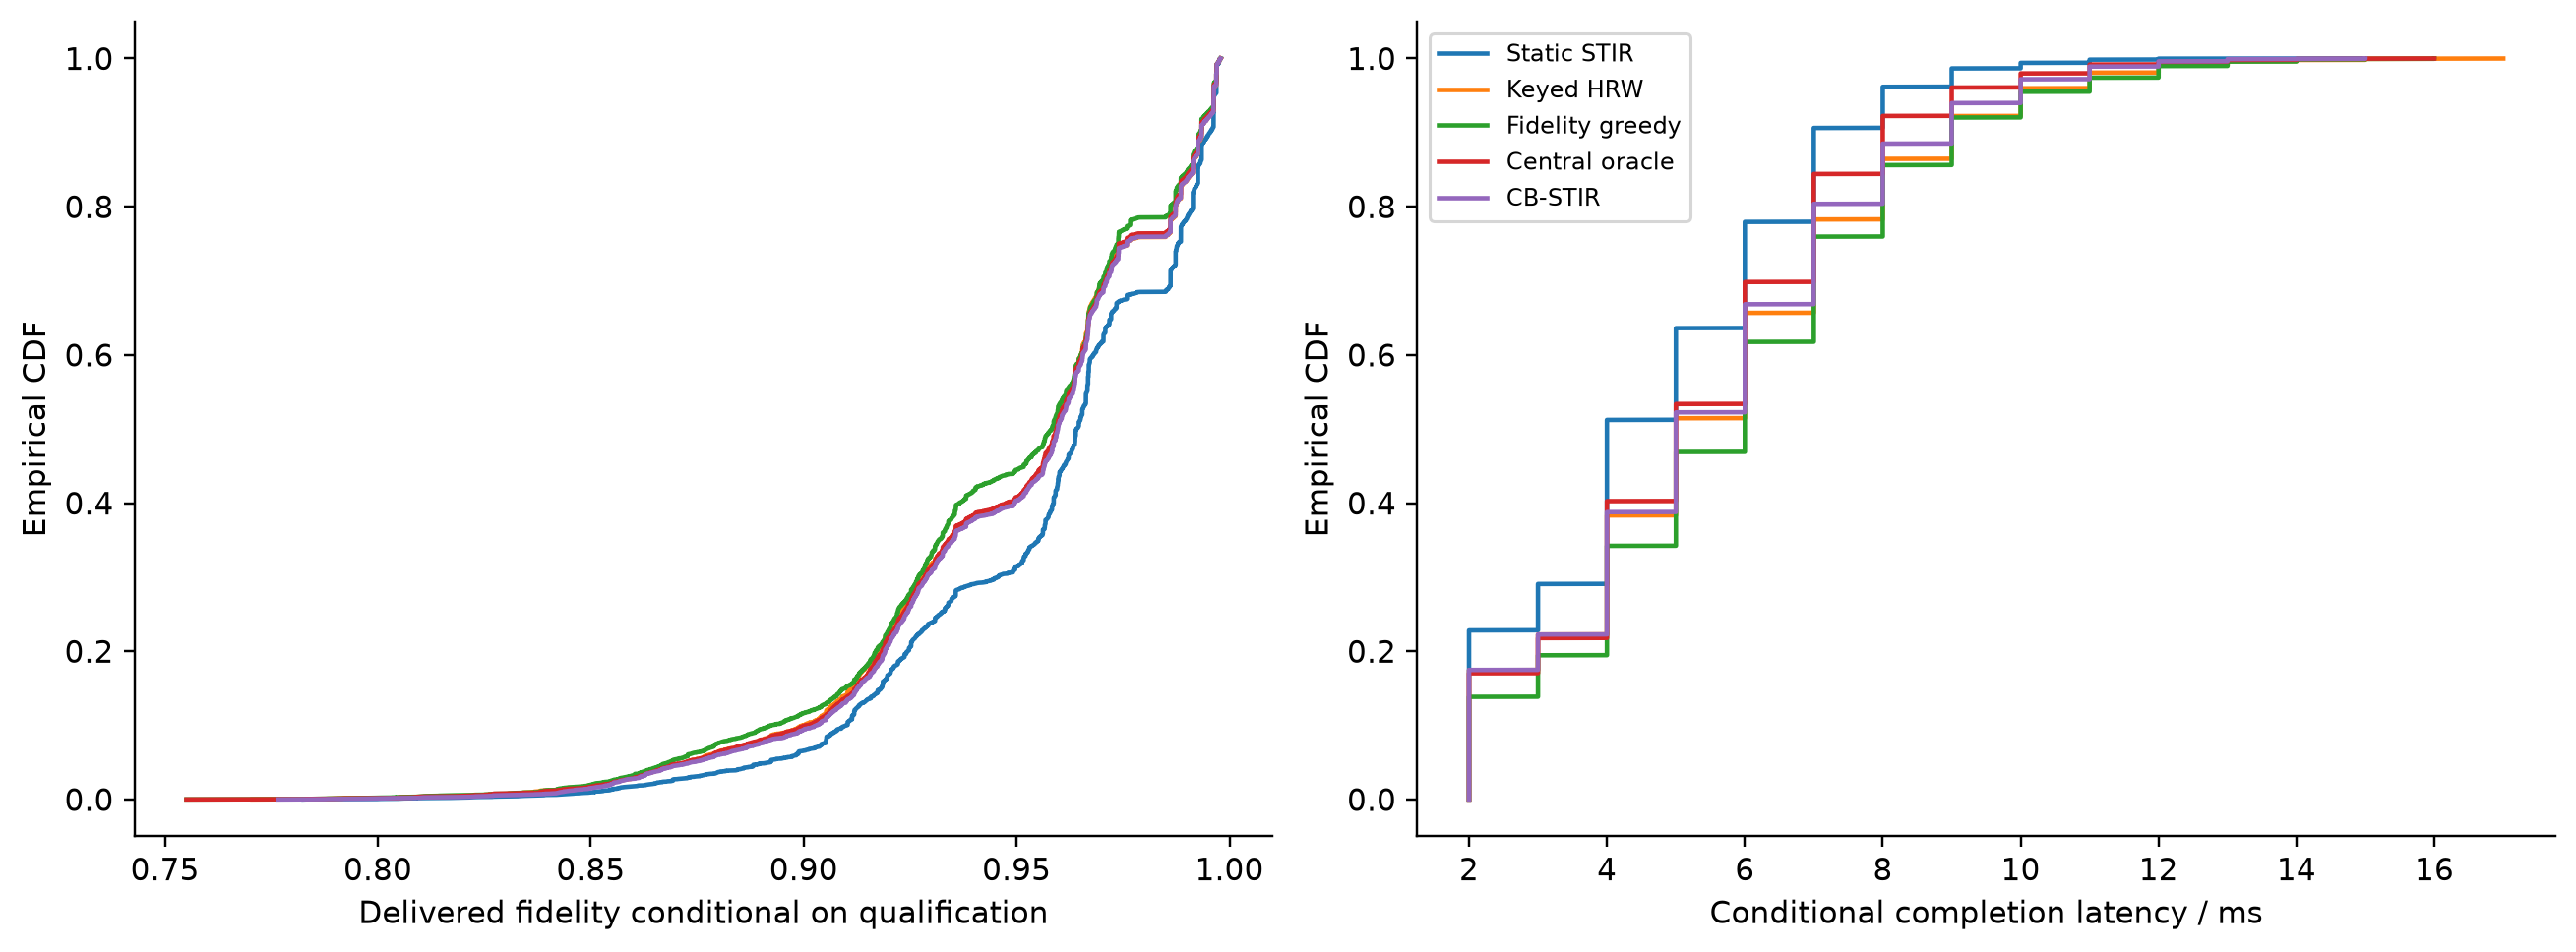

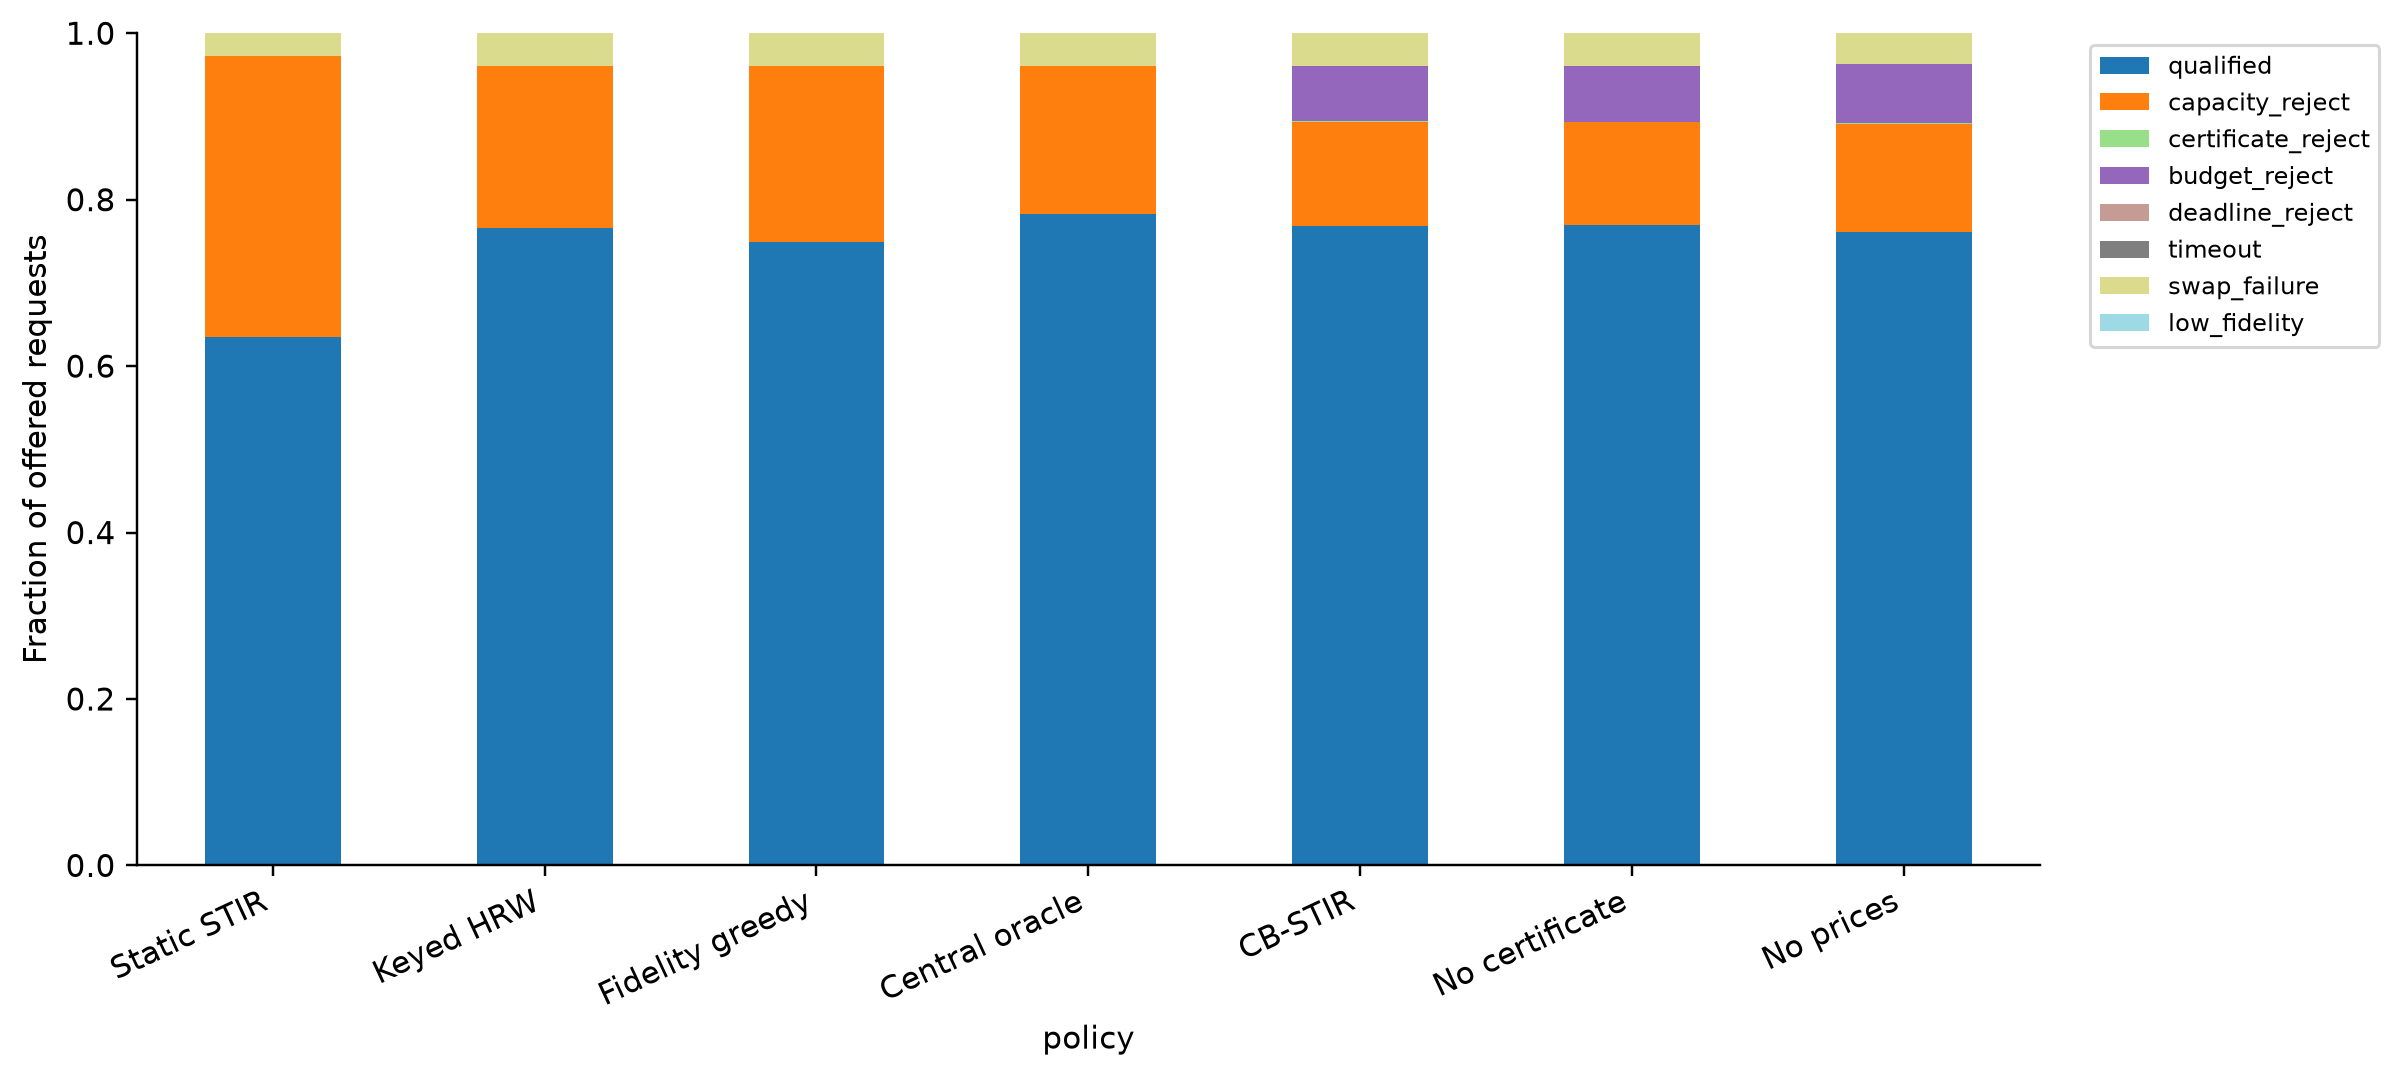

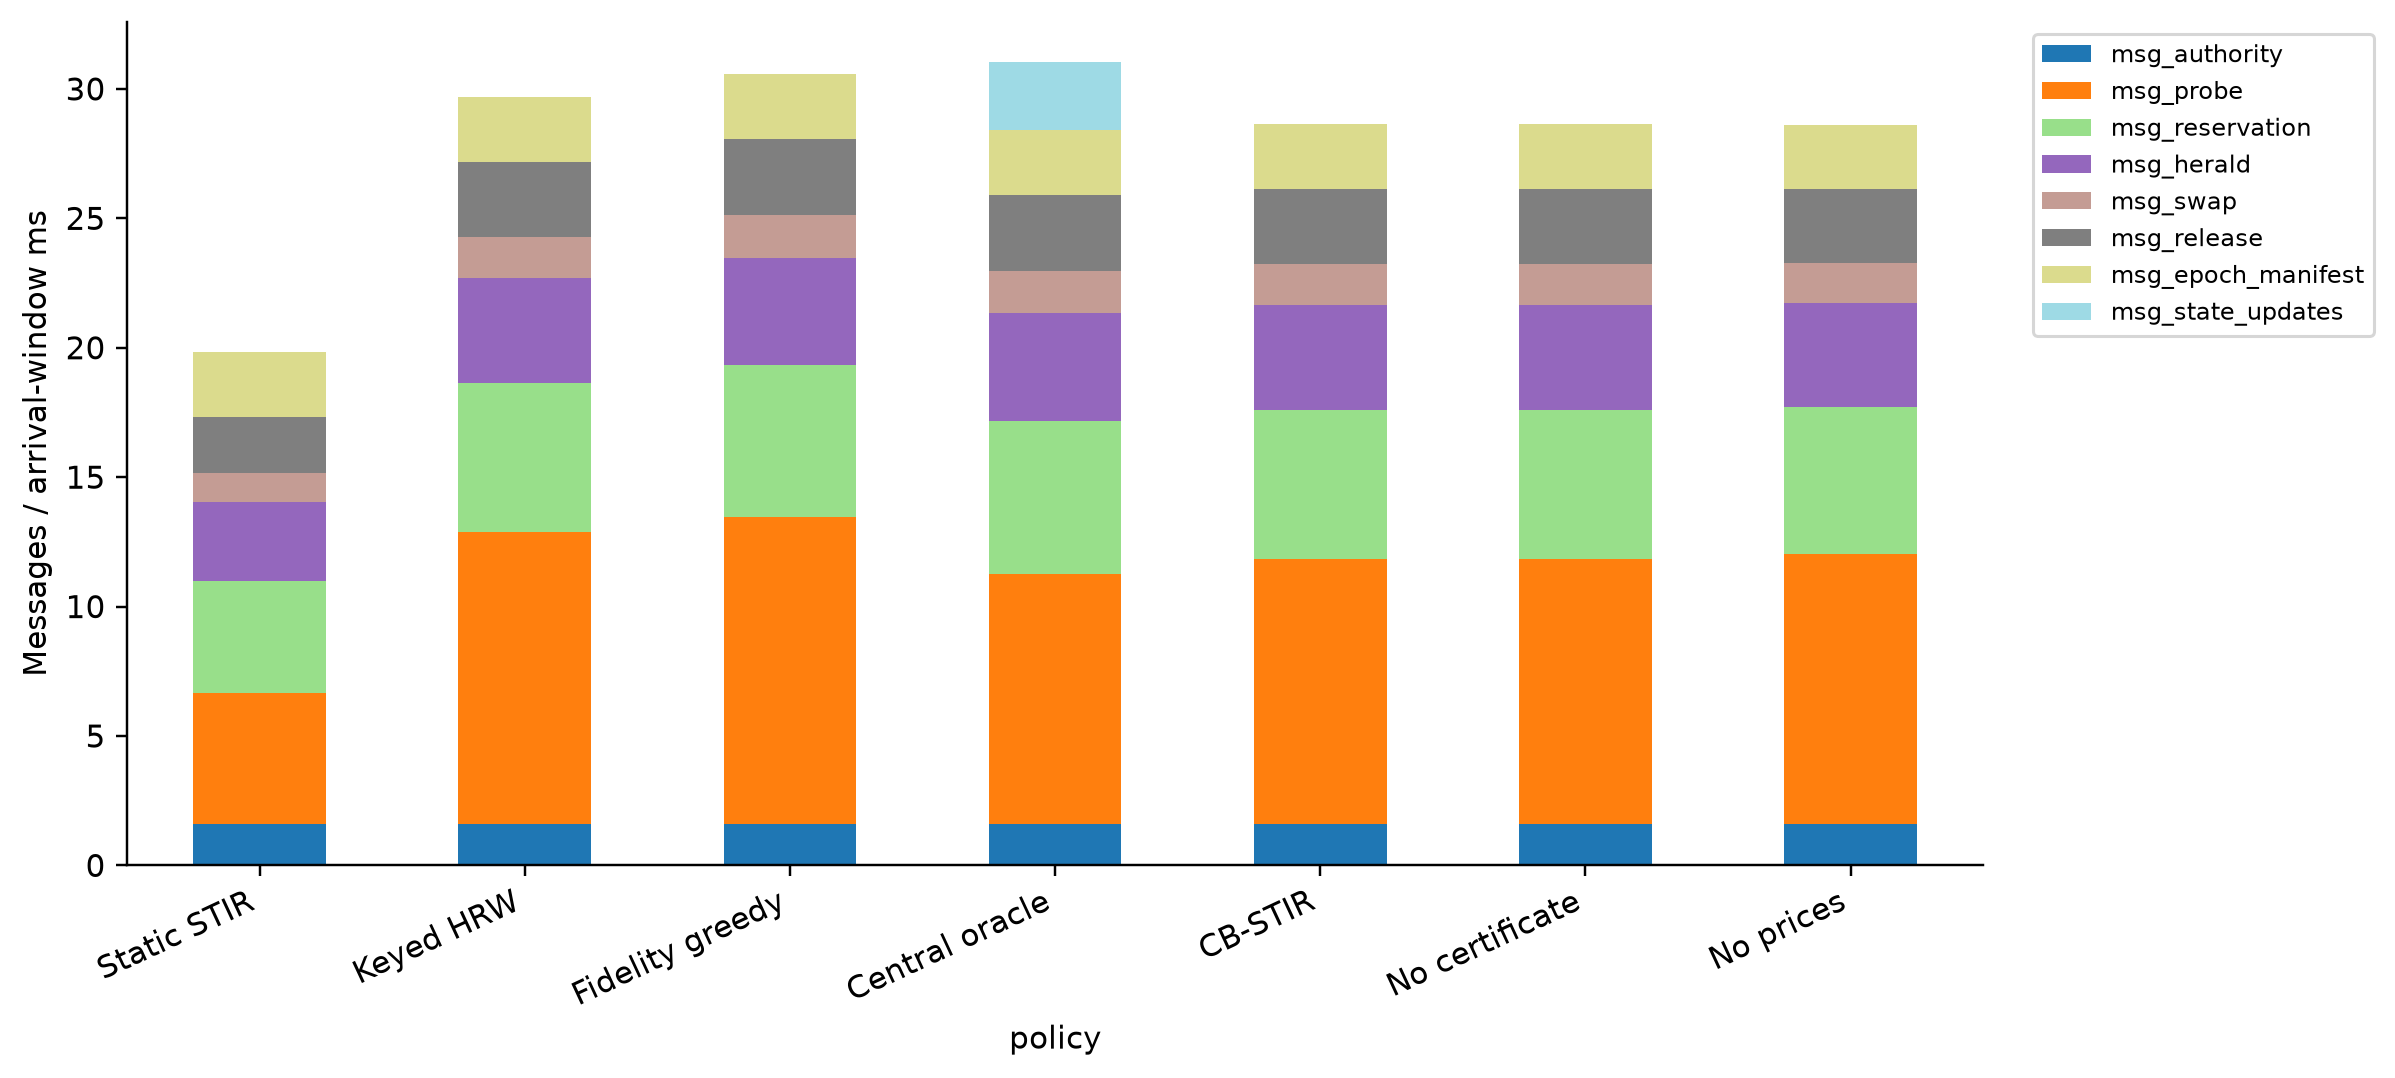

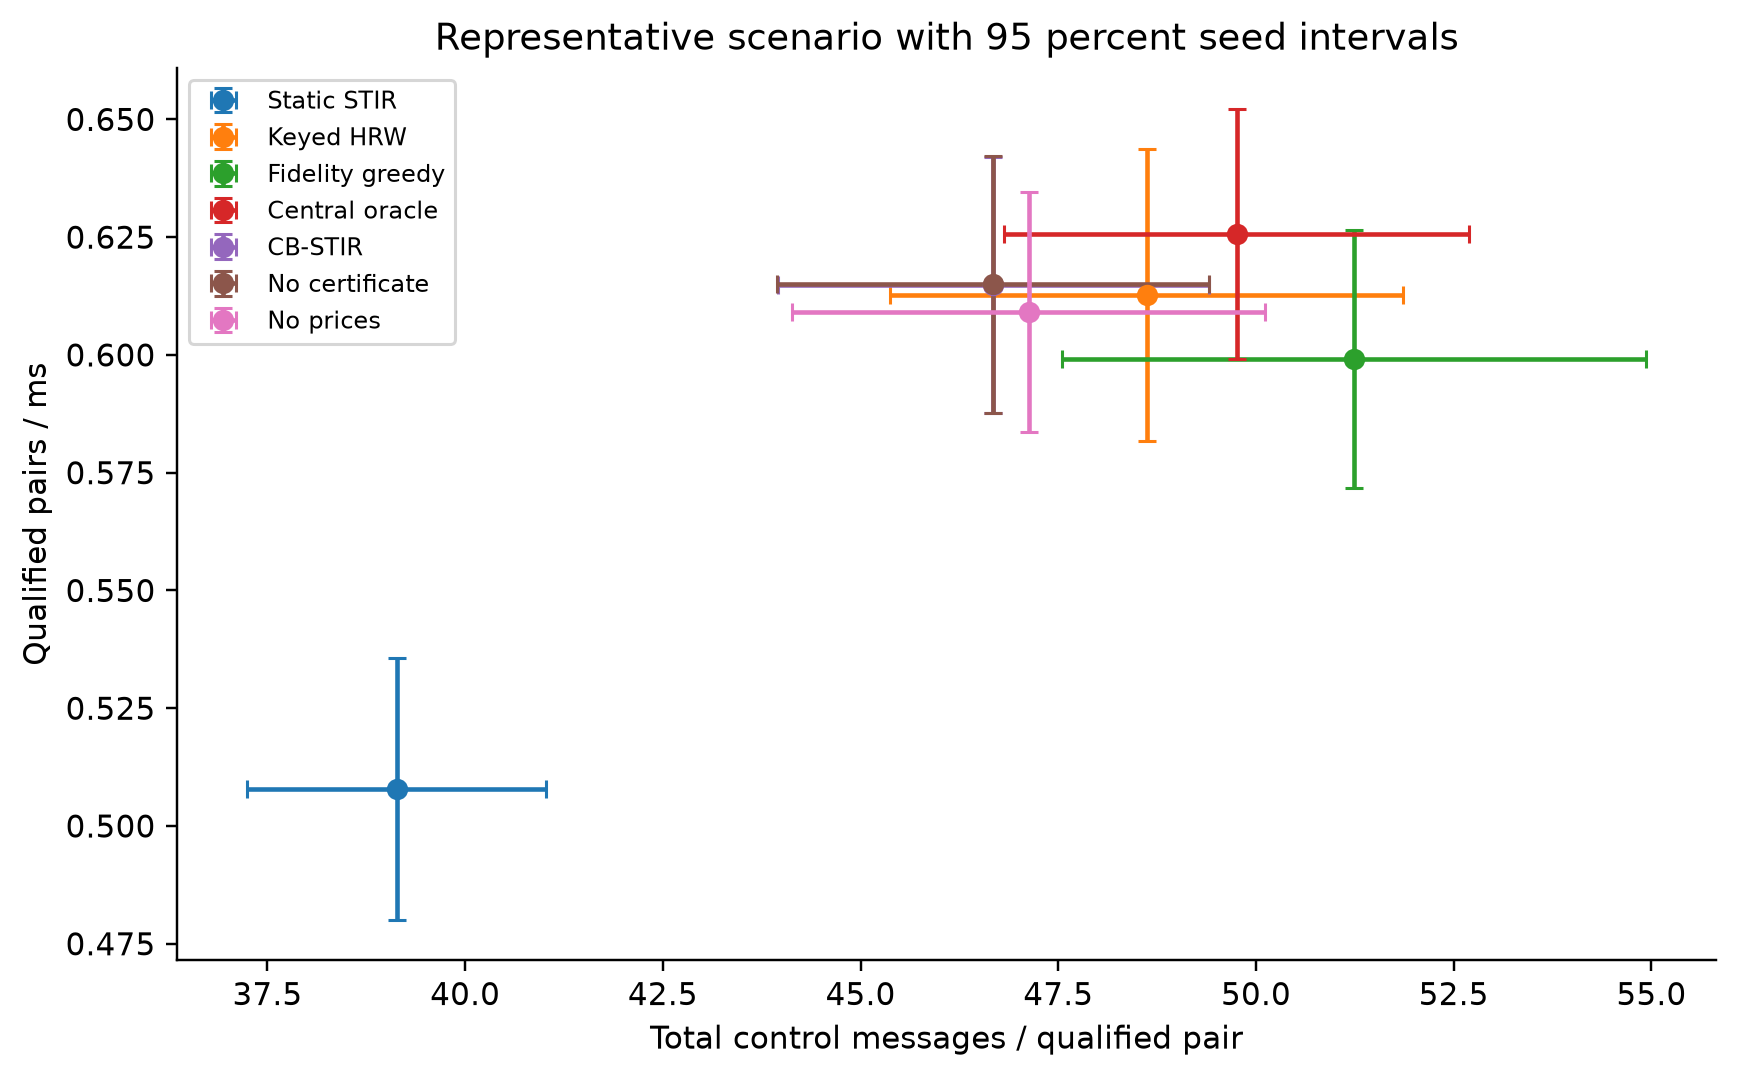

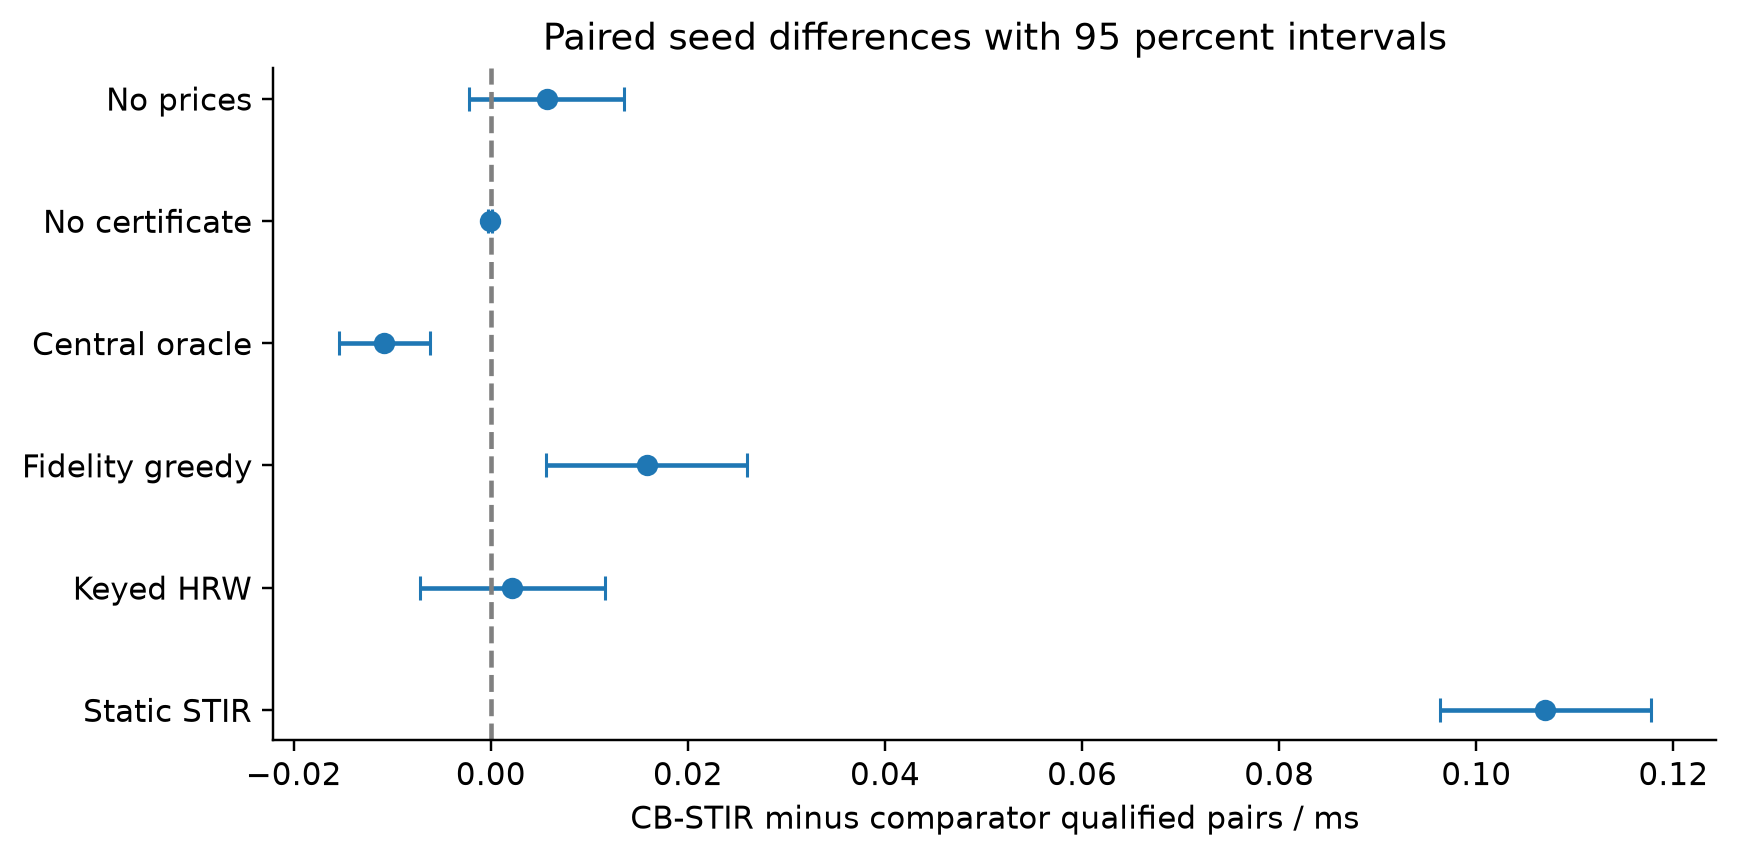

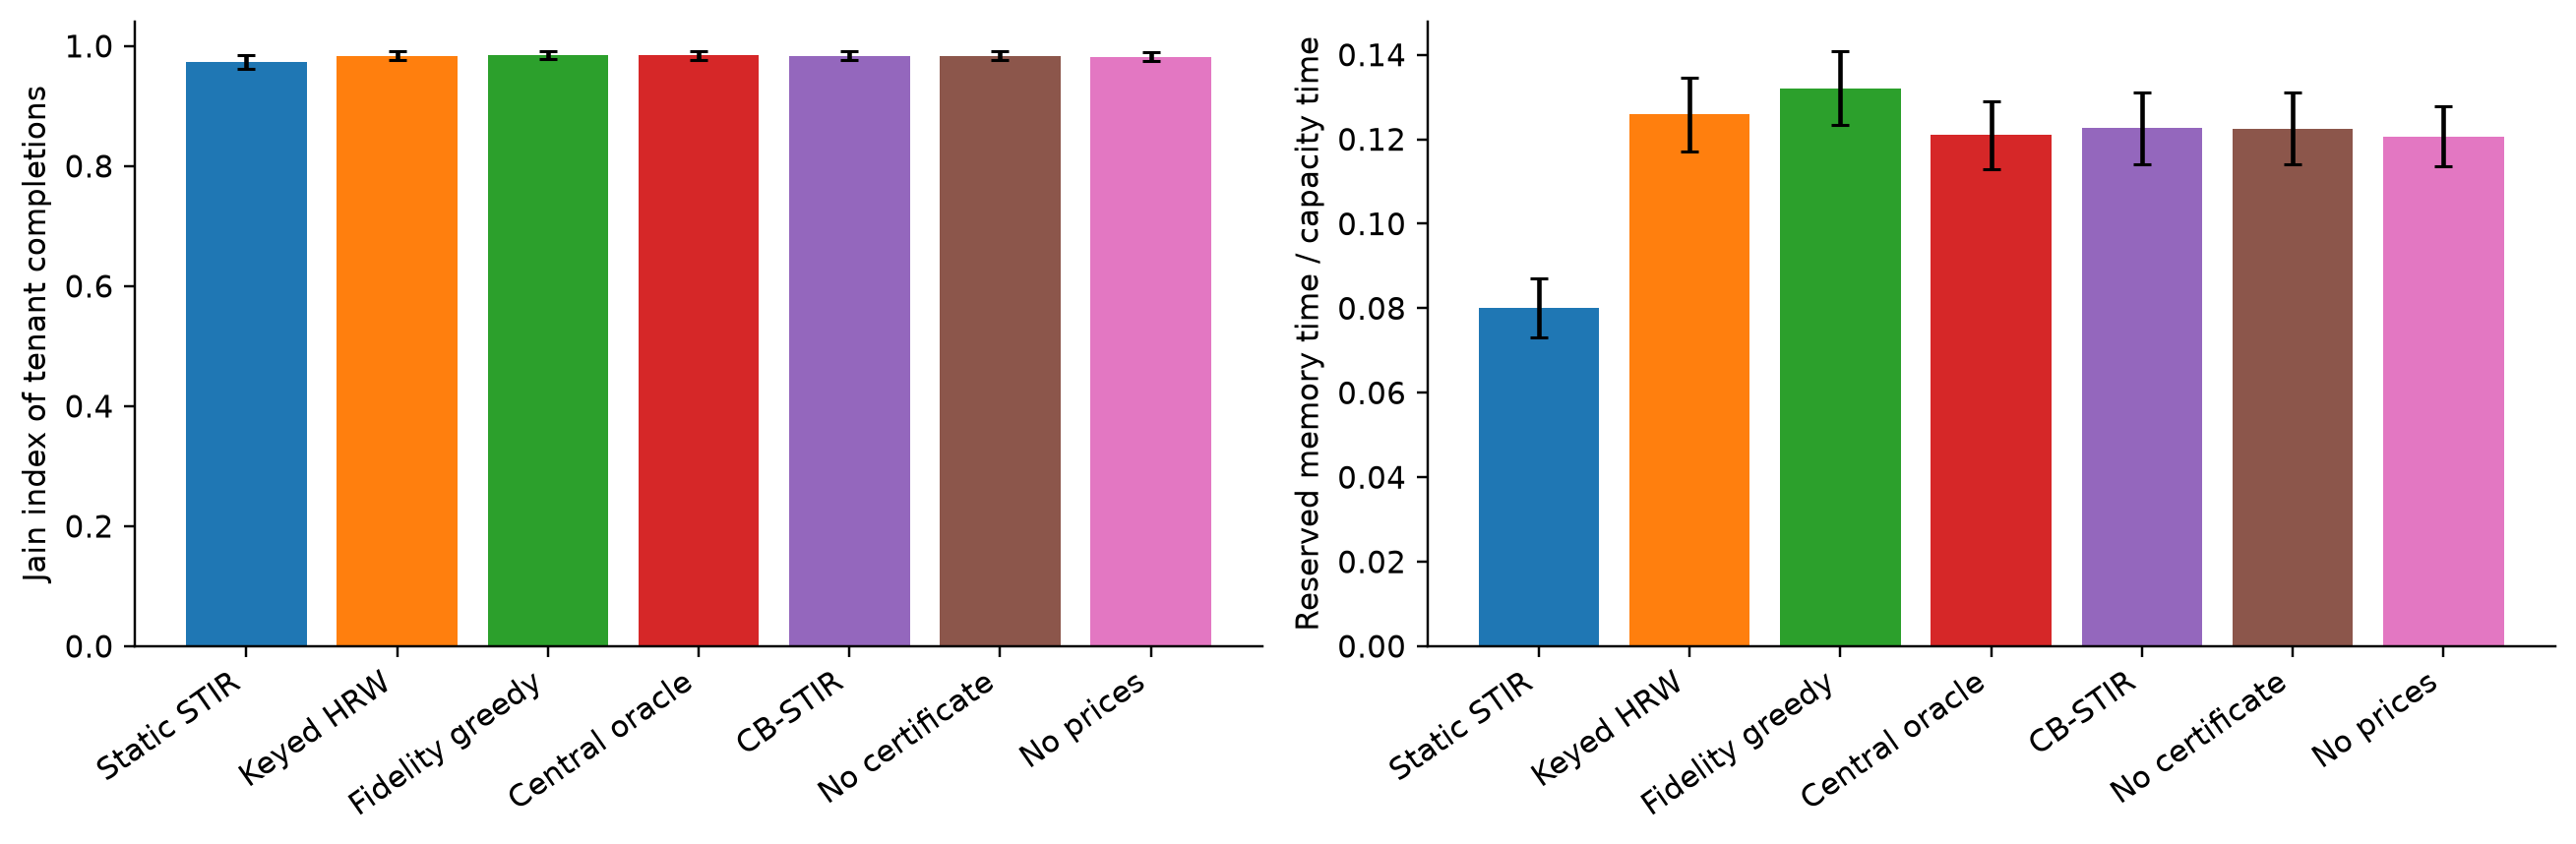

In [5]:
# Figure 1 topology and link quality
adj,props=make_graph('grid',25,0);fig,ax=plt.subplots(figsize=(7,6))
for (u,v),p in props.items():
    ax.plot([u%5,v%5],[u//5,v//5],color=plt.cm.viridis(p['p']),lw=2)
for v in adj:
    ax.scatter(v%5,v//5,s=180,color='white',edgecolor='black',zorder=3)
    ax.text(v%5,v//5,str(v),ha='center',va='center',zorder=4,fontsize=8)
ax.set(title='25-node grid with heterogeneous link generation',xlabel='Grid column',ylabel='Grid row');fig.tight_layout();plt.show()
# Figures 2 and 3 goodput load sweeps, t intervals
for T in [40,100]:
    fig,axs=plt.subplots(1,2,figsize=(12,4.5),sharey=True)
    for ax,kind in zip(axs,['grid','smallworld']):
        for pol in POLICIES[:5]:
            sub=results.query('topology==@kind and T==@T and policy==@pol')
            vals=[mean_ci(sub[sub.rate==r].goodput) for r in [.3,.8,1.5]]
            ax.errorbar([.3,.8,1.5],[x[0] for x in vals],yerr=[x[1] for x in vals],label=pol,color=COLORS[pol],marker='o',capsize=3)
        ax.set(title=f'{kind}, effective lifetime {T} ms',xlabel='Offered requests / ms',ylabel='Qualified pairs / ms')
    axs[1].legend(fontsize=8);fig.tight_layout();plt.show()
# Figure 4 fidelity and conditional latency distributions
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
for pol in POLICIES[:5]:
    sub=requests[(requests.policy==pol)&(requests.status=='qualified')]
    for ax,col in zip(axs,['fidelity','latency']):
        vals=np.sort(sub[col].dropna());ax.plot(vals,np.arange(1,len(vals)+1)/max(len(vals),1),label=pol,color=COLORS[pol])
axs[0].set(xlabel='Delivered fidelity conditional on qualification',ylabel='Empirical CDF')
axs[1].set(xlabel='Conditional completion latency / ms',ylabel='Empirical CDF');axs[1].legend(fontsize=8)
fig.tight_layout();plt.show()
# Figure 5 outcome accounting
status_order=['qualified','capacity_reject','certificate_reject','budget_reject','deadline_reject','timeout','swap_failure','low_fidelity']
ct=pd.crosstab(requests.policy,requests.status).reindex(POLICIES).reindex(columns=status_order,fill_value=0)
(ct.div(ct.sum(axis=1),axis=0)).plot.bar(stacked=True,figsize=(11,5),colormap='tab20')
plt.ylabel('Fraction of offered requests');plt.xticks(rotation=25,ha='right');plt.legend(bbox_to_anchor=(1.02,1),fontsize=8);plt.tight_layout();plt.show()
# Figure 6 control message breakdown
rep=results.query("topology=='smallworld' and rate==.8 and T==100")
msgcols=[c for c in rep if c.startswith('msg_') and c!='msg_delay']
(rep.groupby('policy')[msgcols].mean().reindex(POLICIES)/1000).plot.bar(stacked=True,figsize=(11,5),colormap='tab20')
plt.ylabel('Messages / arrival-window ms');plt.xticks(rotation=25,ha='right');plt.legend(bbox_to_anchor=(1.02,1),fontsize=8);plt.tight_layout();plt.show()
# Figure 7 goodput and control-cost Pareto scatter
fig,ax=plt.subplots(figsize=(8,5))
for pol in POLICIES:
    x=rep[rep.policy==pol];xm,xc=mean_ci(x.messages_per_qualified);ym,yc=mean_ci(x.goodput)
    ax.errorbar(xm,ym,xerr=xc,yerr=yc,fmt='o',capsize=3,label=pol,color=COLORS[pol])
ax.set(xlabel='Total control messages / qualified pair',ylabel='Qualified pairs / ms',title='Representative scenario with 95 percent seed intervals');ax.legend(fontsize=8);fig.tight_layout();plt.show()
# Figure 8 paired ablation intervals
ab=paired.query("topology=='smallworld' and rate==.8 and T==100 and metric=='goodput'")
fig,ax=plt.subplots(figsize=(8,4))
ax.errorbar(ab.difference,np.arange(len(ab)),xerr=(ab.ci_high-ab.ci_low)/2,fmt='o',capsize=4)
ax.axvline(0,color='grey',ls='--');ax.set_yticks(np.arange(len(ab)),ab.baseline)
ax.set(xlabel='CB-STIR minus comparator qualified pairs / ms',title='Paired seed differences with 95 percent intervals');fig.tight_layout();plt.show()
# Figure 9 fairness and memory utilization
fig,axs=plt.subplots(1,2,figsize=(12,4))
for ax,metric,label in [(axs[0],'fairness','Jain index of tenant completions'),(axs[1],'memory_utilization','Reserved memory time / capacity time')]:
    means=[mean_ci(rep[rep.policy==p][metric]) for p in POLICIES]
    ax.bar(range(len(POLICIES)),[v[0] for v in means],yerr=[v[1] for v in means],color=[COLORS[p] for p in POLICIES],capsize=3)
    ax.set_xticks(range(len(POLICIES)),POLICIES,rotation=35,ha='right');ax.set_ylabel(label)
fig.tight_layout();plt.show()


## Sensitivity and calibration
These parameter sweeps were defined before examining outcomes. They include short and long coherence lifetimes, small probe budgets, stale epochs and topology sizes. The conservative certificate can reject feasible requests; both reduced waste and lost goodput are reported. No hyperparameters are tuned on the reported seeds.

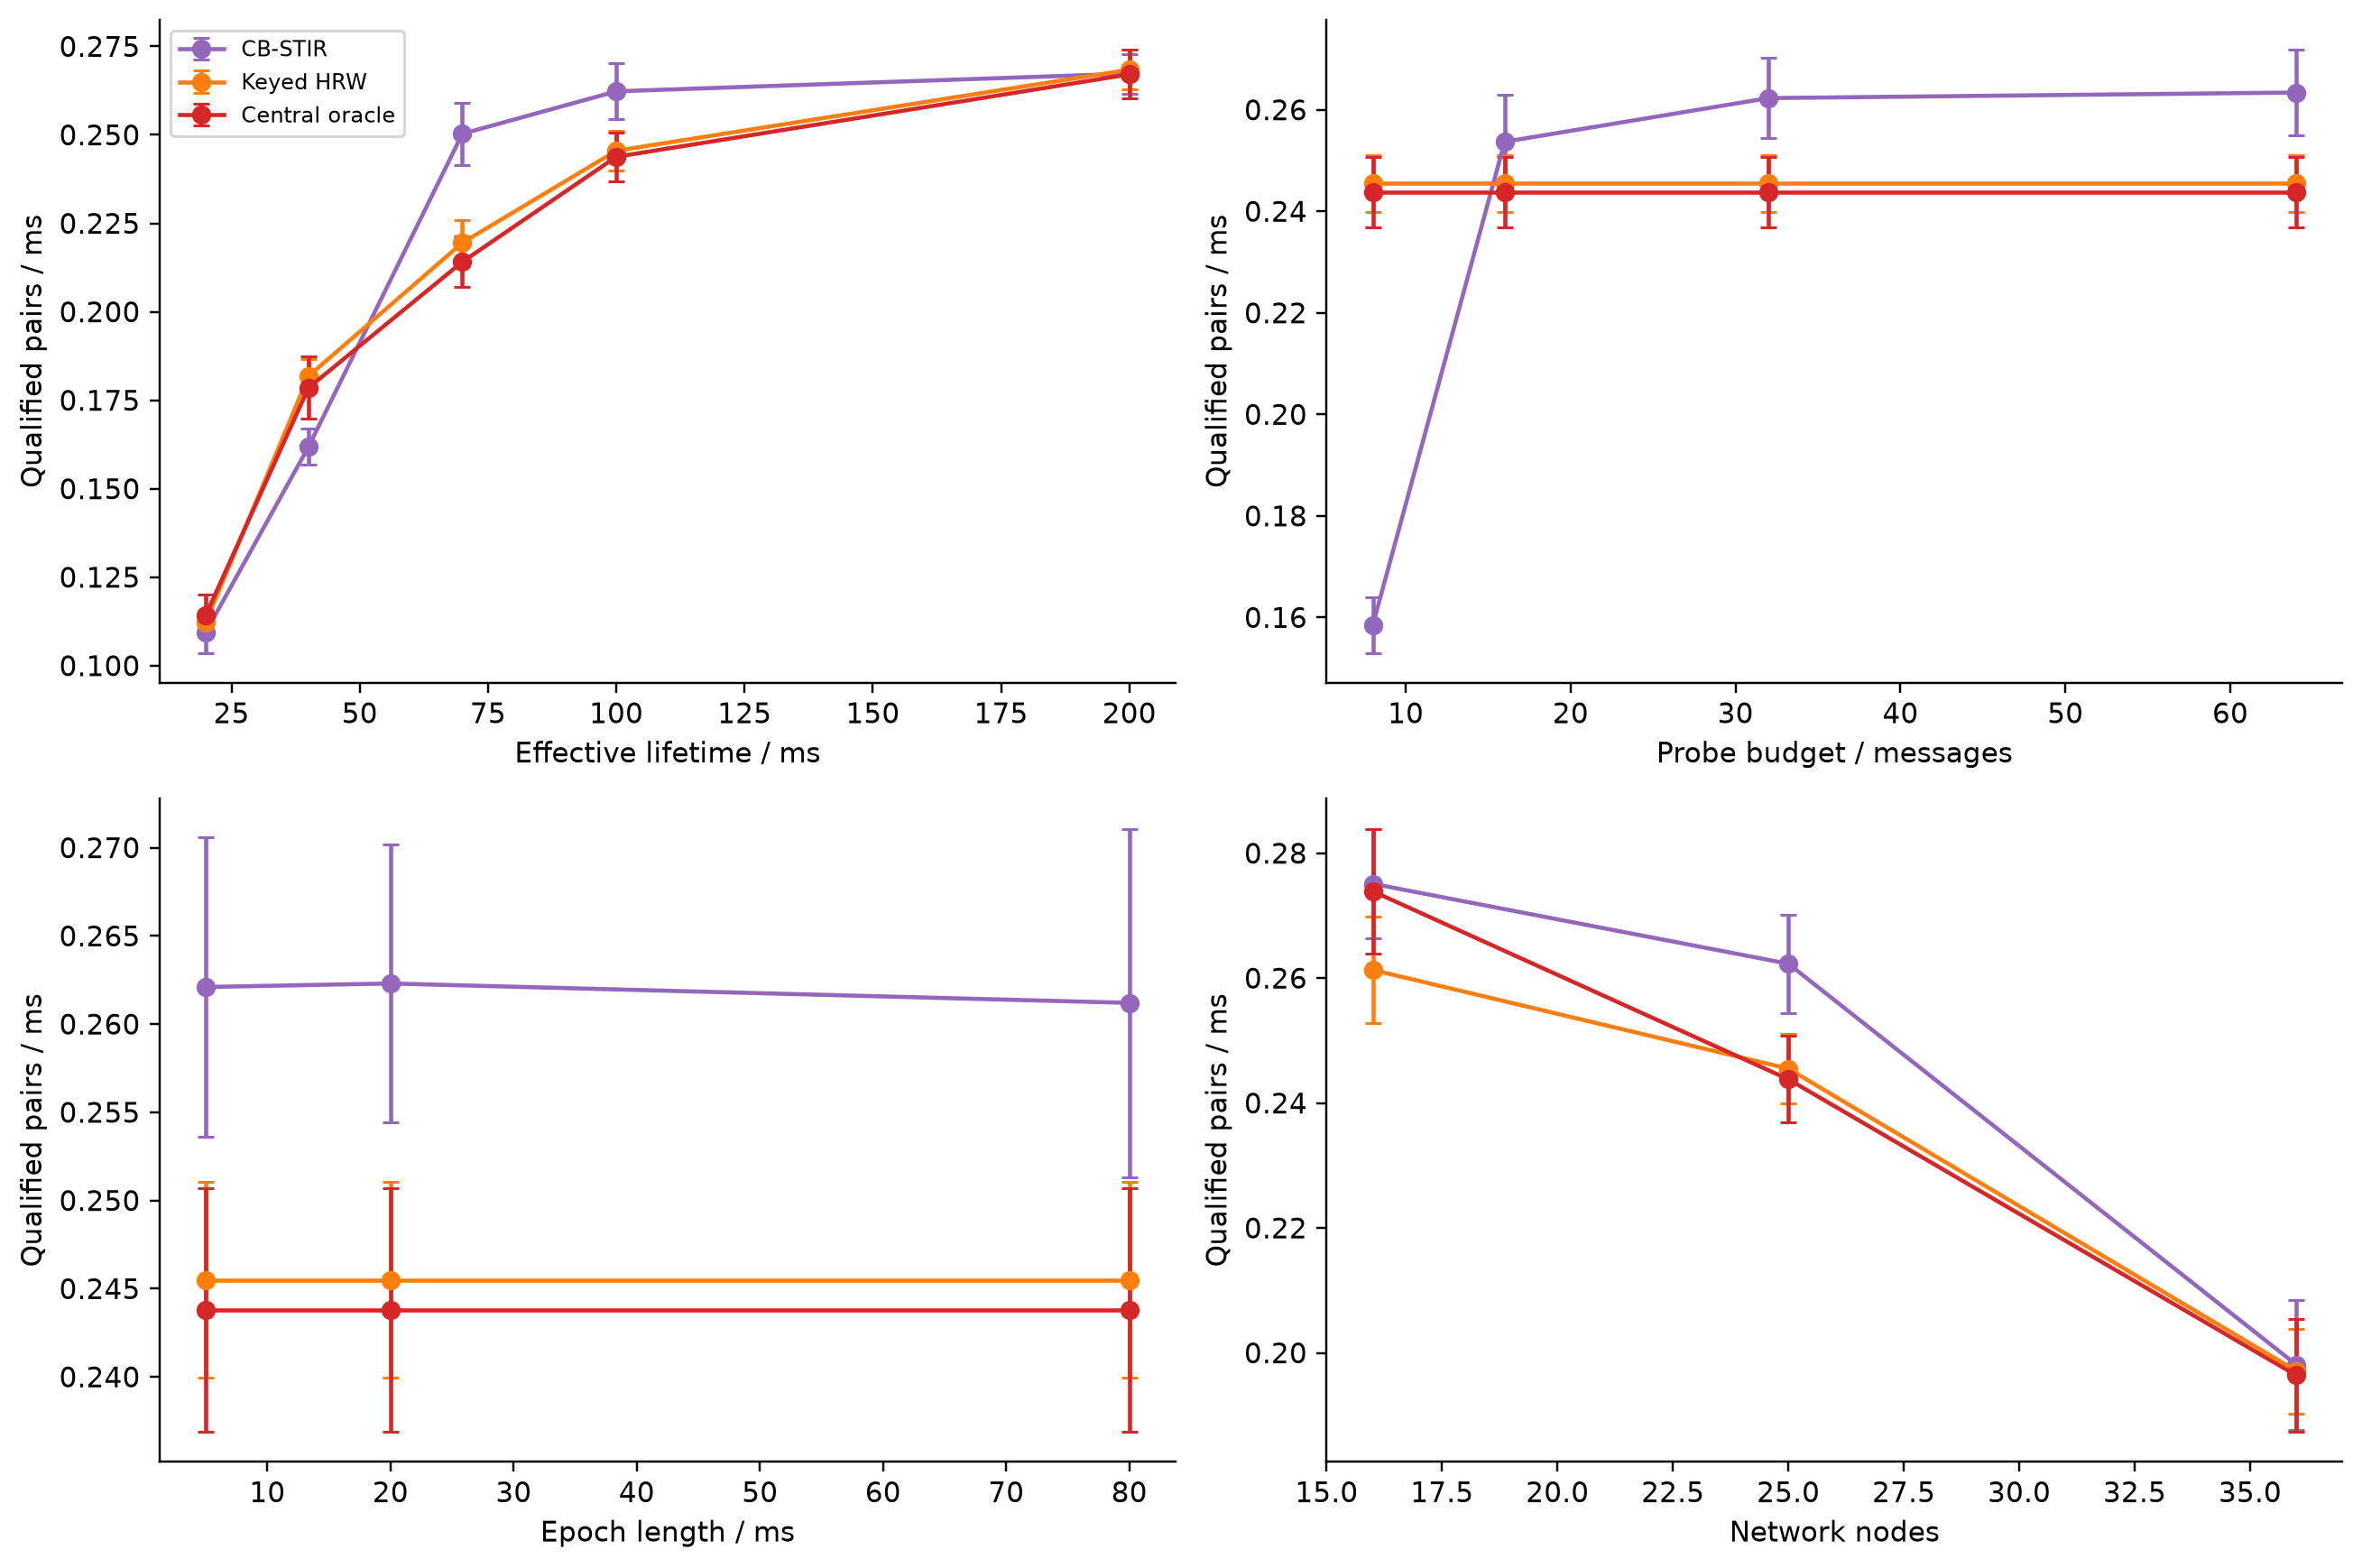

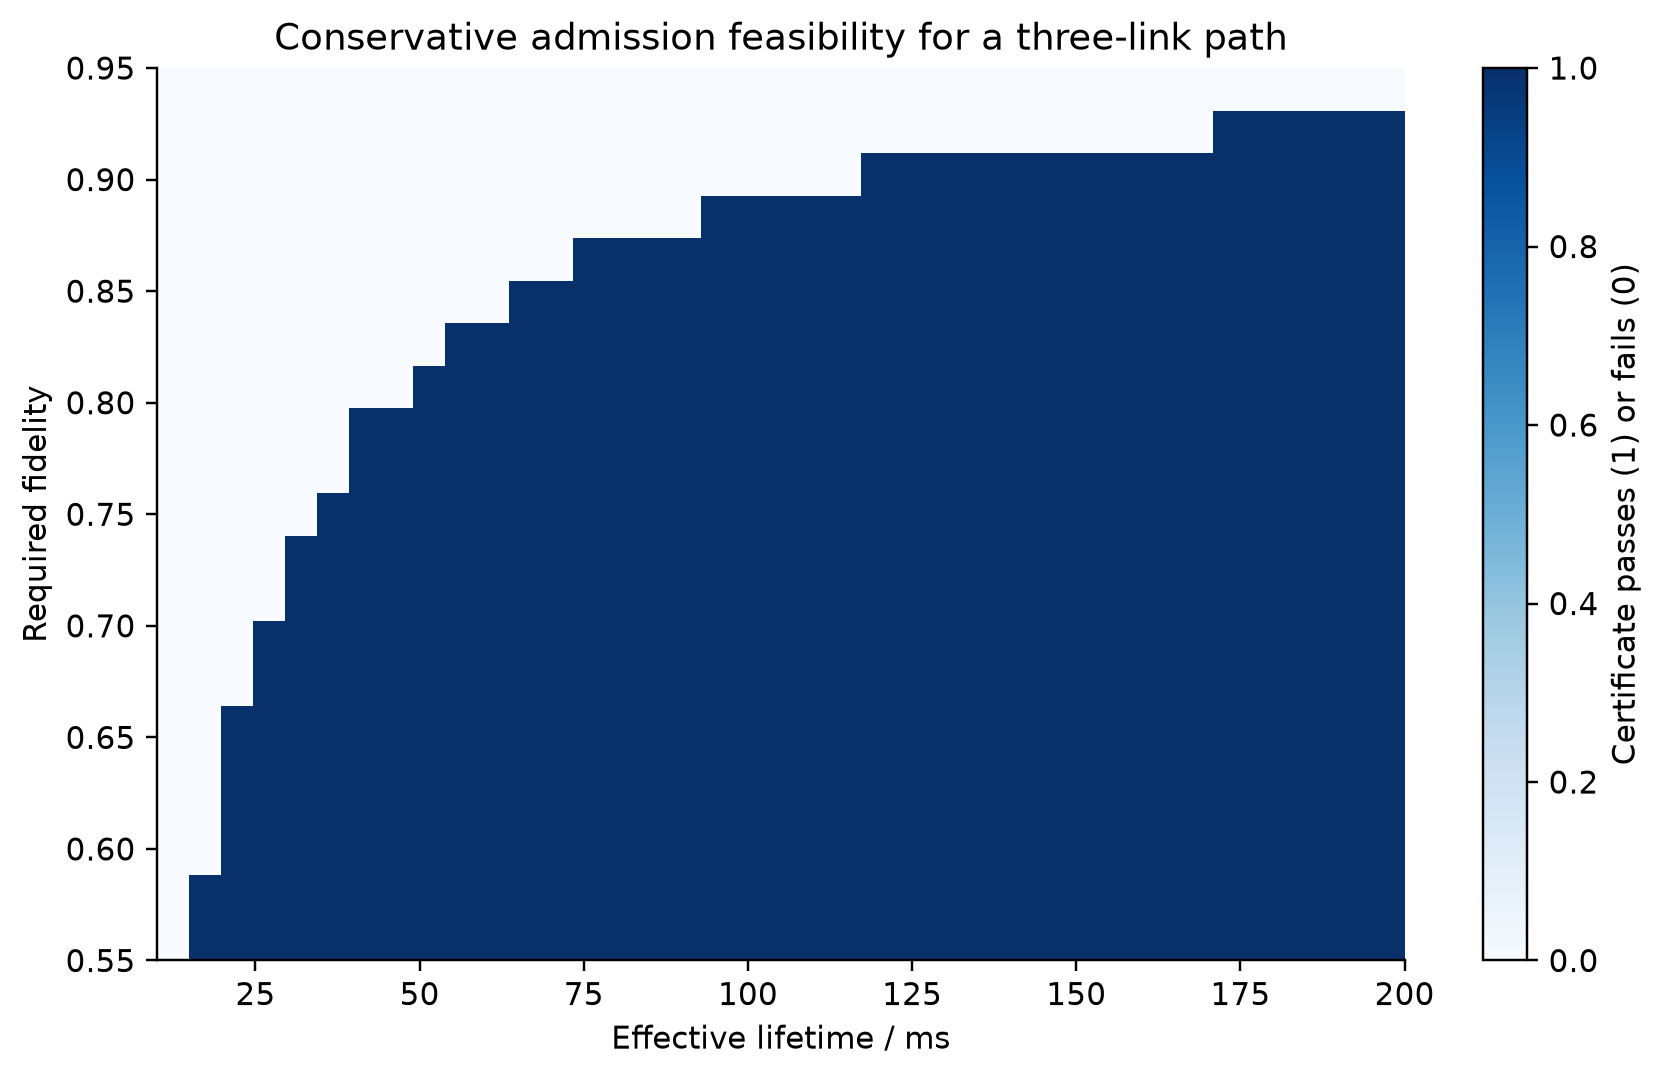

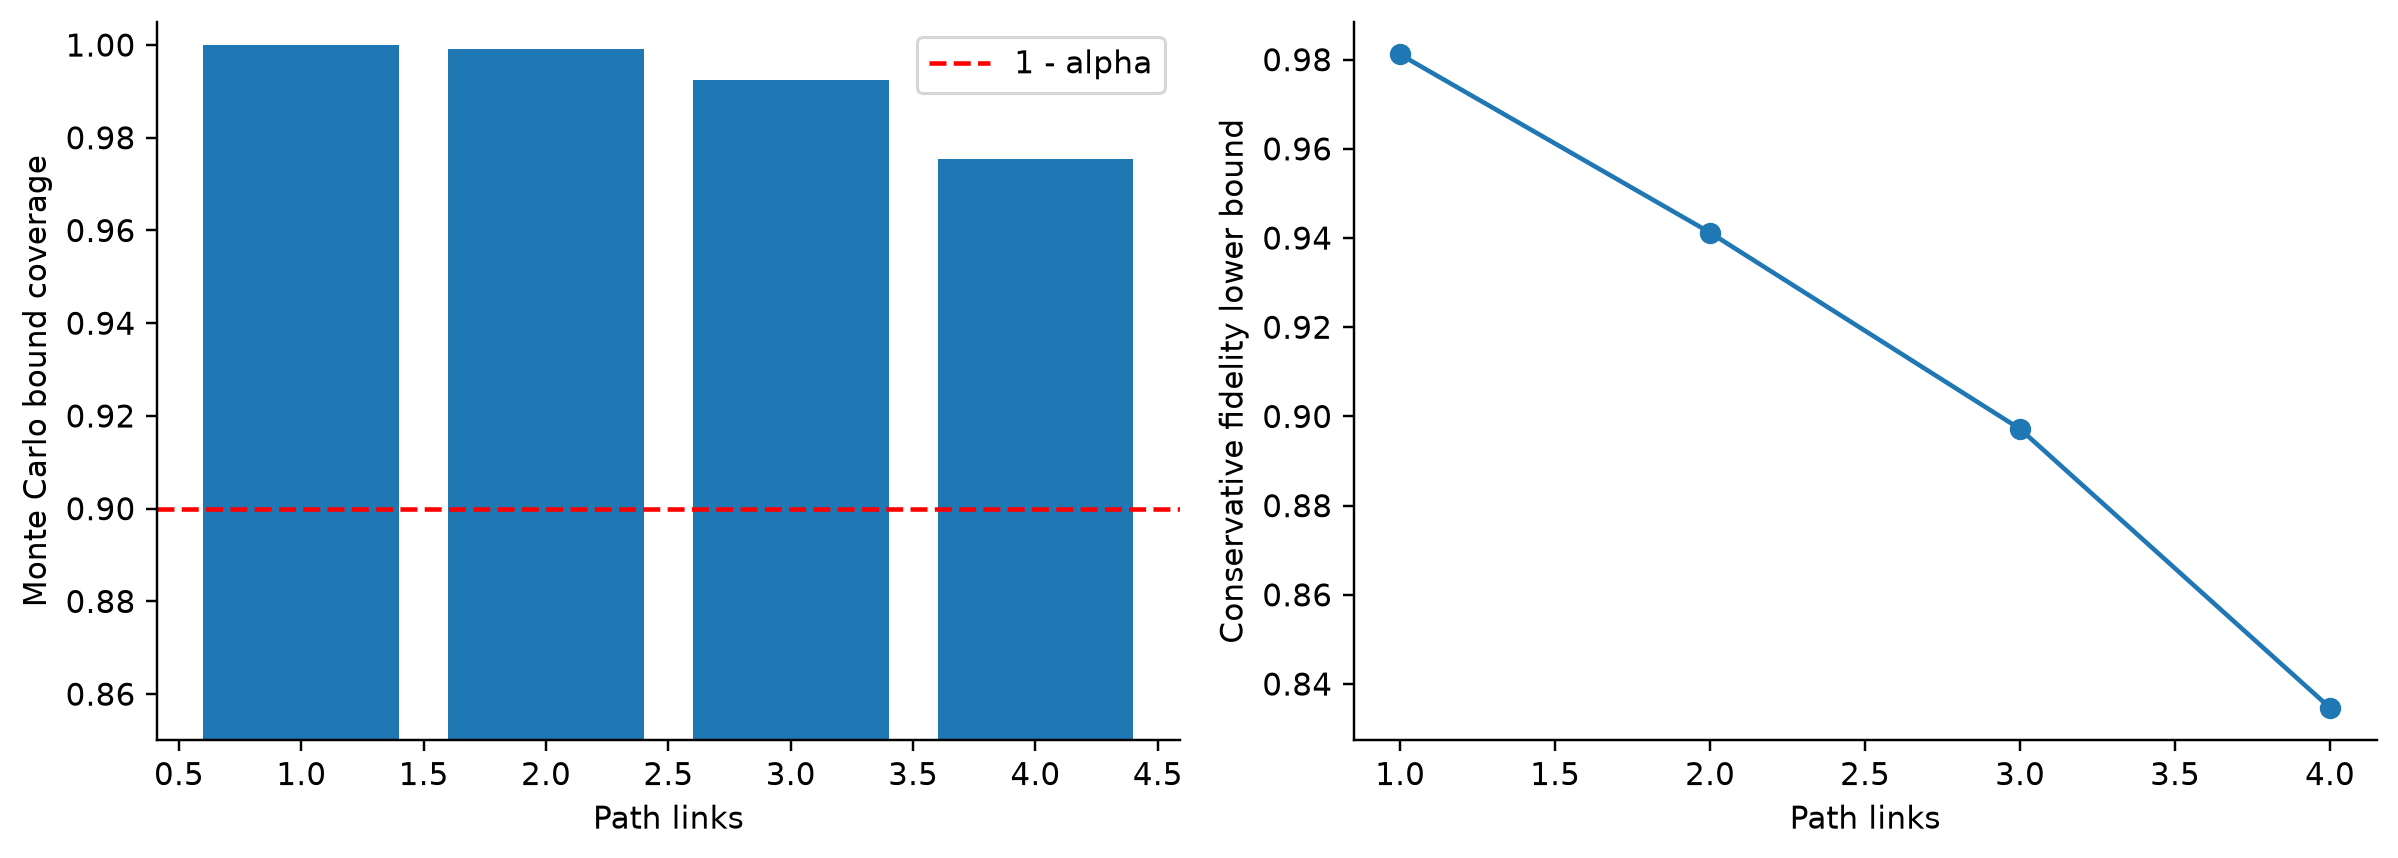

 hops  lower  generation_cap  empirical_coverage  theoretical_minimum  samples
    1 0.9812               2              1.0000                  0.9    20000
    2 0.9412               3              0.9992                  0.9    20000
    3 0.8972               3              0.9925                  0.9    20000
    4 0.8347               3              0.9755                  0.9    20000


In [6]:
sens=[]
for parameter,values in [('T',[20,40,70,100,200]),('budget',[8,16,32,64]),('epoch_len',[5,20,80]),('n',[16,25,36])]:
    for value in values:
        for seed in SEEDS:
            for pol in ['CB-STIR','Keyed HRW','Central oracle']:
                opts=dict(kind='grid',seed=seed,rate=.8,T=100,n=25,policy=pol)
                opts[parameter]=value
                s,_=simulate(**opts);s['sweep_parameter']=parameter;s['sweep_value']=value;sens.append(s)
sensitivity=pd.DataFrame(sens);sensitivity.to_csv(OUT/'sensitivity_summary.csv',index=False)
# Figure 10 sensitivity grid
fig,axs=plt.subplots(2,2,figsize=(12,8))
for ax,par in zip(axs.flat,['T','budget','epoch_len','n']):
    for pol in ['CB-STIR','Keyed HRW','Central oracle']:
        sub=sensitivity.query('sweep_parameter==@par and policy==@pol');vs=sorted(sub.sweep_value.unique())
        estimates=[mean_ci(sub[sub.sweep_value==v].goodput) for v in vs]
        ax.errorbar(vs,[a[0] for a in estimates],yerr=[a[1] for a in estimates],marker='o',capsize=3,label=pol,color=COLORS[pol])
    ax.set(xlabel={'T':'Effective lifetime / ms','budget':'Probe budget / messages','epoch_len':'Epoch length / ms','n':'Network nodes'}[par],ylabel='Qualified pairs / ms')
axs[0,0].legend(fontsize=8);fig.tight_layout();plt.show()
# Figure 11 certificate feasibility surface on one fixed three-link chain
p3=(0,1,2,3);_,props=make_graph('grid',25,0)
Ts=np.arange(10,201,5);targets=np.arange(.55,.96,.02)
Z=np.array([[certificate(p3,props,T)[0]>=f for T in Ts] for f in targets],float)
fig,ax=plt.subplots(figsize=(8,5));im=ax.imshow(Z,origin='lower',aspect='auto',extent=[Ts[0],Ts[-1],targets[0],targets[-1]],cmap='Blues',vmin=0,vmax=1)
ax.set(xlabel='Effective lifetime / ms',ylabel='Required fidelity',title='Conservative admission feasibility for a three-link path');fig.colorbar(im,ax=ax,label='Certificate passes (1) or fails (0)');fig.tight_layout();plt.show()
# Independent certificate coverage Monte Carlo on fixed paths
cal=[]
for h in [1,2,3,4]:
    path=tuple(range(h+1));lo,g=certificate(path,props,100)
    rng=np.random.default_rng(882+h);es=[edge(a,b) for a,b in zip(path,path[1:])]
    draws=np.column_stack([rng.geometric(props[e]['p'],size=20000) for e in es])
    ages=draws.max(axis=1)[:,None]-draws+(h-1)*SWAP_DELAY
    vis=np.prod([(4*props[e]['F']-1)/3 for e in es])*SWAP_V**(h-1)*np.exp(-ages.sum(axis=1)/100)
    fs=(1+3*vis)/4
    cal.append({'hops':h,'lower':lo,'generation_cap':g,'empirical_coverage':float((fs>=lo).mean()),'theoretical_minimum':1-ALPHA,'samples':len(fs)})
calibration=pd.DataFrame(cal);calibration.to_csv(OUT/'certificate_coverage.csv',index=False)
# Figure 12 certificate calibration and conservatism
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].bar(calibration.hops,calibration.empirical_coverage);axs[0].axhline(1-ALPHA,color='red',ls='--',label='1 - alpha')
axs[0].set(ylim=(.85,1.005),xlabel='Path links',ylabel='Monte Carlo bound coverage');axs[0].legend()
axs[1].plot(calibration.hops,calibration.lower,marker='o');axs[1].set(xlabel='Path links',ylabel='Conservative fidelity lower bound')
fig.tight_layout();plt.show();print(calibration.round(4).to_string(index=False))


## Epoch fencing, retries and privacy counterexamples
Weighted keyed rendezvous mapping is $\arg\min_i -\log U_{tenant,seat,epoch,i}/c_i$, with stable tie breaking. A request pins its epoch at ingress; no fallback may change it unilaterally. Replicas refuse epochs outside their accepted manifest. An old epoch may remain valid for already admitted jobs until drained; it must not acquire new resources. Exactly-once effects require a durable request ledger in addition to mapping.

The following state machine tests assume a single authoritative epoch register and request ledger. They validate expected transitions, not a distributed fencing implementation. Failure injection deliberately demonstrates why mapping alone is insufficient. HMAC prevents prediction at unqueried inputs under a secret key and a suitable observation model; it does not hide observed owner labels. The key in this notebook is public for reproducibility and provides no deployed confidentiality.

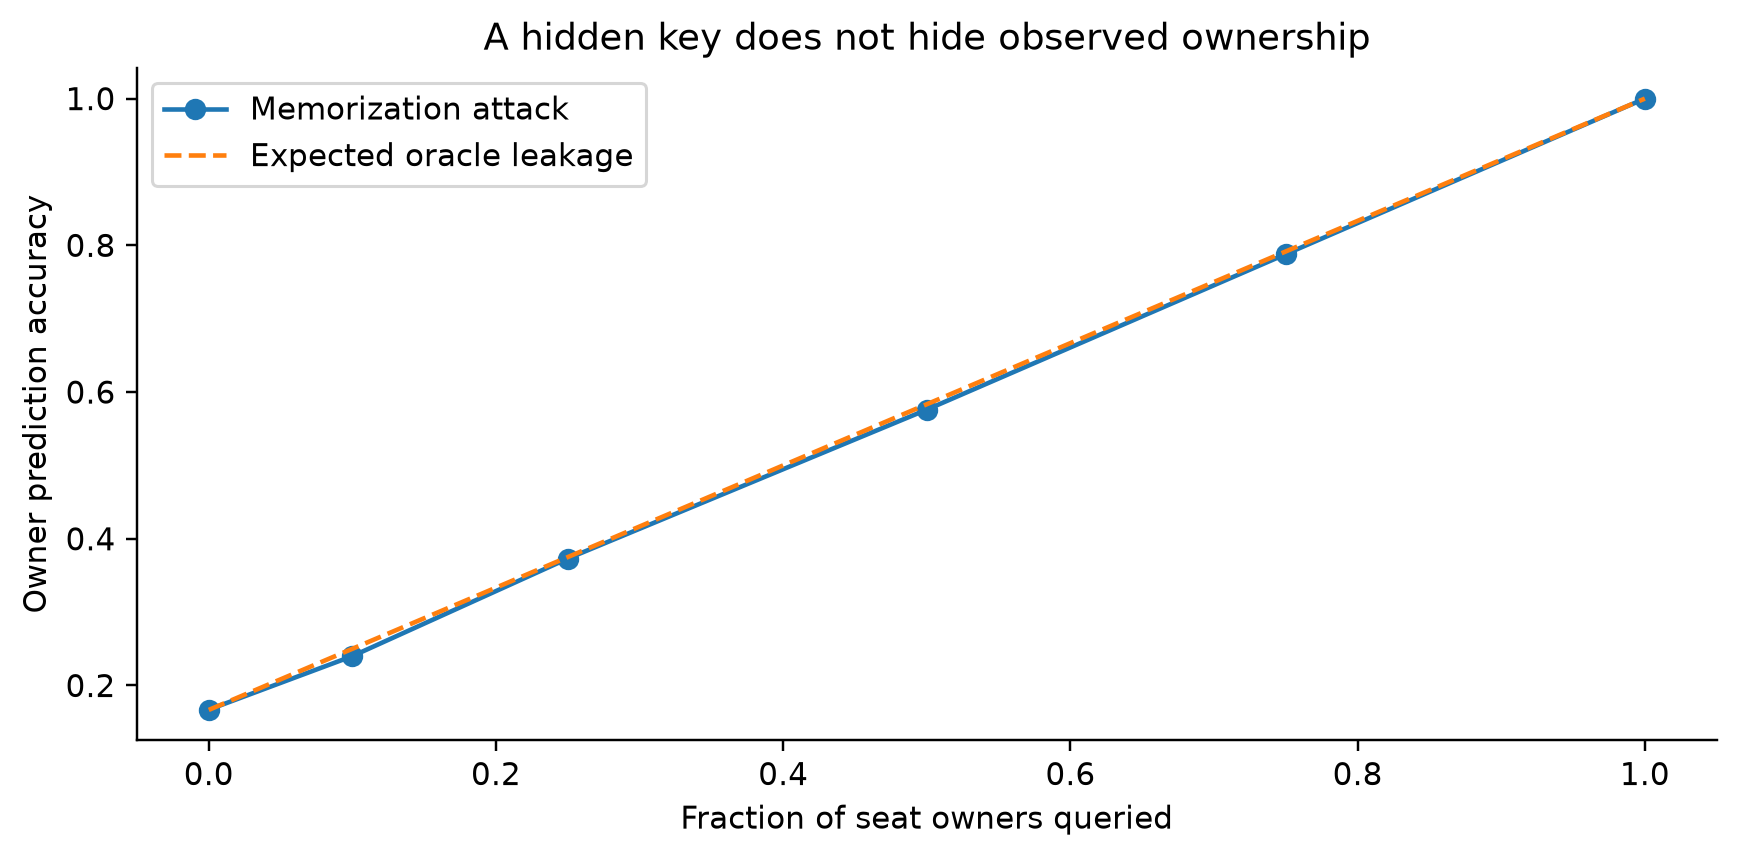

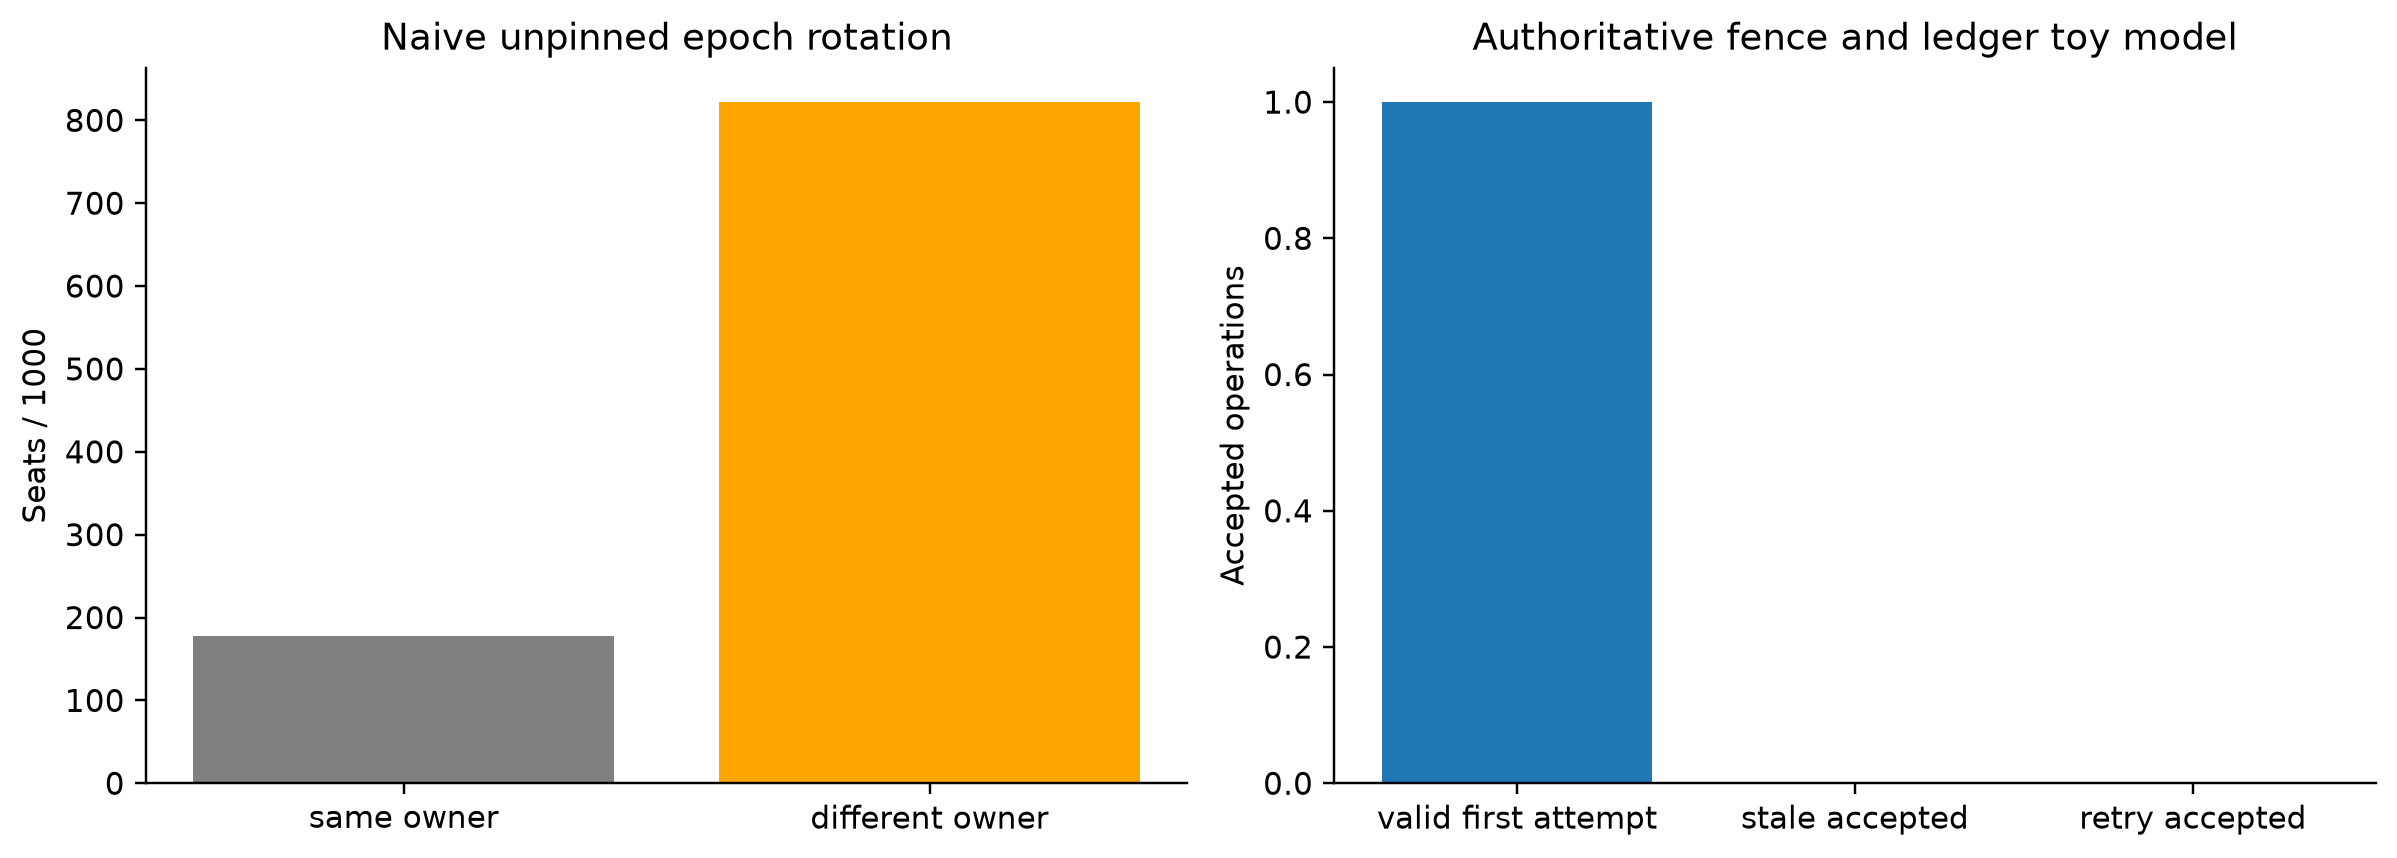

                                test  observations  count
 Epoch disagreement different owners          1000    822
      Stale epoch rejected by ledger             1      1
Duplicate request rejected by ledger             1      1


In [7]:
class FenceLedger:
    def __init__(self,epoch=1):self.epoch=epoch;self.seen=set()
    def acquire(self,request_id,epoch):
        if epoch!=self.epoch:return 'stale_epoch'
        if request_id in self.seen:return 'duplicate'
        self.seen.add(request_id);return 'accepted'
ledger=FenceLedger()
assert ledger.acquire('r1',0)=='stale_epoch'
assert ledger.acquire('r1',1)=='accepted'
assert ledger.acquire('r1',1)=='duplicate'
# The same request handled in differing epochs can acquire two distinct naive owners.
seats=range(1000);different=sum(owner(0,r,0)!=owner(0,r,1) for r in seats)
# Explicit query oracle reveals observed owners; a memorizing adversary succeeds on queried seats.
rng=np.random.default_rng(44);truth=np.array([owner(0,r,0) for r in range(1000)])
attack=[]
for fraction in [0,.1,.25,.5,.75,1]:
    known=set(rng.choice(1000,int(1000*fraction),replace=False))
    guess=np.array([truth[r] if r in known else rng.integers(6) for r in range(1000)])
    attack.append(dict(queried_fraction=fraction,empirical_accuracy=float((guess==truth).mean()),expected_accuracy=fraction+(1-fraction)/6))
attack=pd.DataFrame(attack);attack.to_csv(OUT/'ownership_oracle_attack.csv',index=False)
safety=pd.DataFrame([{'test':'Epoch disagreement different owners','observations':1000,'count':different},
                    {'test':'Stale epoch rejected by ledger','observations':1,'count':1},
                    {'test':'Duplicate request rejected by ledger','observations':1,'count':1}])
safety.to_csv(OUT/'safety_counterexamples.csv',index=False)
# Figure 13 mapping leakage counterexample
fig,ax=plt.subplots(figsize=(8,4));ax.plot(attack.queried_fraction,attack.empirical_accuracy,'o-',label='Memorization attack');ax.plot(attack.queried_fraction,attack.expected_accuracy,'--',label='Expected oracle leakage')
ax.set(xlabel='Fraction of seat owners queried',ylabel='Owner prediction accuracy',title='A hidden key does not hide observed ownership');ax.legend();fig.tight_layout();plt.show()
# Figure 14 epoch instability and request deduplication state machine
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].bar(['same owner','different owner'],[1000-different,different],color=['grey','orange']);axs[0].set(ylabel='Seats / 1000',title='Naive unpinned epoch rotation')
axs[1].bar(['valid first attempt','stale accepted','retry accepted'],[1,0,0]);axs[1].set(ylabel='Accepted operations',title='Authoritative fence and ledger toy model')
fig.tight_layout();plt.show();print(safety.to_string(index=False))


## Interpretation and remaining validation
The output below is generated from the actual experiment table. It must be read together with per-scenario seed intervals and failure accounting. Selection bias in conditional fidelity or latency is avoided by also reporting offered-request success. A strong result can be reduced waste at a throughput cost; it is not automatically better service.

The implementation does not benchmark published RADAR-Q, Q-GUARD, DFER or NetSquid. Before journal submission: reproduce their applicable baselines, implement delayed local messages and partitions, measure packet bytes and actual ingress dispatch, calibrate physical parameters, and test weighted authority load with a finite owner CPU queue. Here the owner identity is bookkeeping only, so authority assignment cannot explain simulated quantum goodput. Quantum resource reservations remain coordinated. No cryptographic privacy, optimality, hardware performance, or unconditional exactly-once guarantee is claimed.

In [8]:
keycase=results.query("topology=='smallworld' and rate==.8 and T==100")
table=keycase.groupby('policy')[['goodput','success_fraction','messages_per_qualified','p95_latency','fairness']].mean().reindex(POLICIES)
table.to_csv(OUT/'representative_results.csv')
print(table.round(4).to_string())
print('CB-STIR minus central oracle by scenario:')
print(paired.query("metric=='goodput' and baseline=='Central oracle'")[['topology','rate','T','difference','ci_low','ci_high']].round(4).to_string(index=False))
config={'seed_list':SEEDS,'horizon_ms':1000,'main_topologies':['grid','smallworld'],'main_nodes':25,
        'rates_per_ms':[.3,.8,1.5],'coherence_ms':[40,100],'Fmin':.72,'swap_success':SWAP_P,
        'swap_visibility':SWAP_V,'swap_delay_ms':SWAP_DELAY,'alpha':ALPHA,
        'epoch_ms':20,'probe_budget_messages':32,'candidate_paths':4,'deadline_ms':30,
        'node_memory_slots':6,'edge_parallel_channels':1,'message_delay_ms':.15,
        'physics':'Werner visibility with effective pair-lifetime; no purification',
        'software':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__}}
(OUT/'configuration.json').write_text(json.dumps(config,indent=2))
print('Saved raw summaries, selected per-request traces, paired intervals, sensitivities, safety counterexamples, calibration and graphs to',OUT)


                 goodput  success_fraction  messages_per_qualified  p95_latency  fairness
policy                                                                                   
Static STIR       0.5079            0.6353                 39.1343        8.055    0.9734
Keyed HRW         0.6127            0.7667                 48.6184       10.145    0.9838
Fidelity greedy   0.5991            0.7503                 51.2400       10.300    0.9847
Central oracle    0.6257            0.7833                 49.7538        9.200    0.9842
CB-STIR           0.6149            0.7697                 46.6787        9.700    0.9837
No certificate    0.6150            0.7698                 46.6744        9.700    0.9839
No prices         0.6092            0.7630                 47.1245        9.770    0.9822
CB-STIR minus central oracle by scenario:
  topology  rate   T  difference  ci_low  ci_high
      grid   0.3  40     -0.0190 -0.0221  -0.0159
      grid   0.3 100     -0.0079 -0.0117  -0.004